<a href="https://colab.research.google.com/github/Abmanna/Abmanna-Omniscient-Multi-Agent-Drug-Discovery-OS-Godly-Generative-Scaffold-Approach/blob/main/GradioCADDPipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# 🧬 High-Throughput CADD & AI Co-Folding Pipeline

This notebook implements an advanced Computer-Aided Drug Design (CADD) workflow, combining physics-based 3D docking, machine learning pharmacophore mapping, and state-of-the-art all-atom co-folding using Boltz-1.

### ⚙️ Pipeline Architecture:
1. **Environment Setup & Binaries:** Installing robust dependencies (RDKit, Py3Dmol, Gradio) and compiling/downloading GNINA.
2. **RCSB PDB Mining & Receptor Prep:** Dynamic GraphQL queries to isolate pathogen targets, extract structural parameters, and auto-detect pockets with Delaunay triangulation/fpocket.
3. **Generative Library & Custom Input Ingestion:** A universal chemical interface supporting file uploads, text lists, and dynamic SAR bioisostere generation.
4. **Physics-Driven Docking & Interaction Profiling:** High-resolution GPU CNN docking using GNINA, 2D/3D interaction profiling, and pose strain analysis.
5. **DL-Based All-Atom Co-Folding:** Verifying shortlisted hits with Boltz-1 prediction and evaluating structural convergence using Kabsch alignment.
```

Lightweight Small-Molecule & Boltz Environment Setup


In [11]:
# =====================================================================
# CELL 1: SMALL-MOLECULE VIRTUAL SCREENING & BOLTZ ENVIRONMENT SETUP
# =====================================================================
import subprocess, sys, os, shutil, re, json, math, time, glob, gzip, hashlib, html, io, itertools, warnings
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import requests

def sh(cmd, check=False):
    return subprocess.run(cmd, shell=True, check=check, capture_output=True, text=True)

print("1/3 Installing RDKit, PoseBusters, Biopython, py3Dmol, Gradio, SELFIES, and Dimorphite-DL...")
sh(f"{sys.executable} -m pip -q install rdkit biopython py3Dmol seaborn tqdm openpyxl scikit-learn requests posebusters gradio pyyaml selfies")
sh("apt-get -qq update && apt-get -qq install -y openbabel fpocket", check=False)

print("2/3 Installing Boltz (Small-Molecule Protein-Ligand Co-Folding)...")
sh(f"{sys.executable} -m pip -q install boltz", check=False)

print("3/3 Installing GNINA (GPU 3D-CNN Docking Engine)...")
WORK = Path('/content/screening_work').resolve()
for d in ('dock', 'library_in', 'boltz_in', 'boltz_out', 'pockets'):
    (WORK / d).mkdir(parents=True, exist_ok=True)
os.chdir(WORK)

GNINA = str(WORK / 'gnina')
USE_GPU = shutil.which('nvidia-smi') is not None

def install_gnina():
    if Path(GNINA).exists() and sh(f"{GNINA} --version").returncode == 0:
        return
    urls = ['https://github.com/gnina/gnina/releases/download/v1.0.3/gnina']
    try:
        rel = requests.get('https://api.github.com/repos/gnina/gnina/releases/latest', timeout=20).json()
        for a in rel.get('assets', []):
            if re.fullmatch(r'gnina(\.[\d.]+)?', a['name']):
                urls.insert(0, a['browser_download_url'])
    except Exception:
        pass
    for u in urls:
        sh(f"wget -q -O {GNINA} {u} && chmod +x {GNINA}")
        if sh(f"{GNINA} --version").returncode == 0:
            break

install_gnina()
print("✅ Ready! GNINA:", sh(f"{GNINA} --version").stdout.splitlines()[:1], "| GPU Available:", USE_GPU)

1/3 Installing RDKit, PoseBusters, Biopython, py3Dmol, Gradio, SELFIES, and Dimorphite-DL...
2/3 Installing Boltz (Small-Molecule Protein-Ligand Co-Folding)...
3/3 Installing GNINA (GPU 3D-CNN Docking Engine)...
✅ Ready! GNINA: ['gnina  master:e9cb230+   Built Feb 11 2023.'] | GPU Available: True


```markdown
## 🔍 Stage 1: Automated RCSB PDB Mining & Receptor Curation

This stage connects to the RCSB Protein Data Bank via standard GraphQL and text search APIs. It automates:
- Structural resolution and free R-factor (`R-free`) filtering.
- Ligand electron density verification ($	{RSCC} \ge 0.85$) to filter low-confidence structures.
- Self-docking/re-docking with **GNINA** to evaluate target druggability and docking accuracy.
- PoseBusters testing to ensure physical validity (no atomic clashes or bond length distortions).
```

Cell 2: Core Cheminformatics, GNINA Docking & 2D/3D Interaction Engine

Run this cell once to load all underlying scientific functions from your original workbook (RCSB GraphQL target discovery, co-crystal burial checks, GNINA execution, PoseBusters verification, RDKit standardization, CNS MPO / drug-likeness scoring, and 2D/3D interaction detection) into the notebook kernel.

In [22]:
# =====================================================================
# CELL 2: CORE SCIENTIFIC ENGINE (RCSB, RDKit, GNINA, POSEBUSTERS, 2D/3D)
# Fully Dynamic for Any Custom User Dataset + Delaunay/fpocket Graphs
# =====================================================================
import os, re, sys, glob, gzip, json, math, time, html, io, hashlib, warnings
from pathlib import Path
from collections import defaultdict
import concurrent.futures
import numpy as np
import pandas as pd
import requests
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree, Delaunay
from Bio.PDB import PDBParser, MMCIFParser, PDBIO, Superimposer, Polypeptide

from rdkit import Chem, RDLogger, RDConfig, DataStructs
from rdkit.Chem import (
    AllChem, Descriptors, Crippen, Lipinski, rdMolDescriptors,
    QED, Draw, rdMolAlign, rdDepictor, BRICS, rdFMCS
)
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.SimDivFilters import rdSimDivPickers

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')

# --- 1. Corrected & Expanded Organism Catalogs ---
ORG_CATALOG = {
    'Protozoa | Leishmania (leishmaniasis)': ('Leishmania', 'protozoa'),
    'Protozoa | Trypanosoma cruzi (Chagas disease)': ('Trypanosoma cruzi', 'protozoa'),
    'Protozoa | Trypanosoma brucei (sleeping sickness)': ('Trypanosoma brucei', 'protozoa'),
    'Protozoa | Plasmodium falciparum (malaria)': ('Plasmodium falciparum', 'protozoa'),
    'Protozoa | Plasmodium vivax (malaria)': ('Plasmodium vivax', 'protozoa'),
    'Protozoa | Plasmodium berghei': ('Plasmodium berghei', 'protozoa'),
    'Protozoa | Toxoplasma gondii': ('Toxoplasma gondii', 'protozoa'),
    'Protozoa | Cryptosporidium parvum': ('Cryptosporidium parvum', 'protozoa'),
    'Protozoa | Giardia duodenalis (lamblia)': ('Giardia duodenalis', 'protozoa'),
    'Amoeba | Entamoeba histolytica (amoebiasis)': ('Entamoeba histolytica', 'protozoa'),
    'Amoeba | Naegleria fowleri': ('Naegleria fowleri', 'protozoa'),
    'Bacteria | Mycobacterium tuberculosis': ('Mycobacterium tuberculosis', 'bacteria'),
    'Bacteria | Mycobacterium leprae': ('Mycobacterium leprae', 'bacteria'),
    'Bacteria | Staphylococcus aureus (incl. MRSA)': ('Staphylococcus aureus', 'bacteria'),
    'Bacteria | Escherichia coli': ('Escherichia coli', 'bacteria'),
    'Bacteria | Pseudomonas aeruginosa': ('Pseudomonas aeruginosa', 'bacteria'),
    'Bacteria | Klebsiella pneumoniae': ('Klebsiella pneumoniae', 'bacteria'),
    'Bacteria | Acinetobacter baumannii': ('Acinetobacter baumannii', 'bacteria'),
    'Bacteria | Enterococcus faecium': ('Enterococcus faecium', 'bacteria'),
    'Bacteria | Streptococcus pneumoniae': ('Streptococcus pneumoniae', 'bacteria'),
    'Bacteria | Helicobacter pylori': ('Helicobacter pylori', 'bacteria'),
    'Bacteria | Salmonella enterica': ('Salmonella enterica', 'bacteria'),
    'Bacteria | Vibrio cholerae': ('Vibrio cholerae', 'bacteria'),              # Fixed taxon mapping
    'Bacteria | Bacillus anthracis': ('Bacillus anthracis', 'bacteria'),
    'Bacteria | Clostridioides difficile': ('Clostridioides difficile', 'bacteria'),
    'Bacteria | Neisseria gonorrhoeae': ('Neisseria gonorrhoeae', 'bacteria'),
    'Bacteria | Treponema pallidum (syphilis)': ('Treponema pallidum', 'bacteria'),
    'Bacteria | Chlamydia trachomatis': ('Chlamydia trachomatis', 'bacteria'),  # Fixed spelling
    'Virus | SARS-CoV-2': ('Severe acute respiratory syndrome coronavirus 2', 'virus'),
    'Virus | SARS-CoV-1': ('Severe acute respiratory syndrome-related coronavirus', 'virus'),
    'Virus | MERS-CoV': ('Middle East respiratory syndrome-related coronavirus', 'virus'),
    'Virus | HIV-1': ('Human immunodeficiency virus 1', 'virus'),
    'Virus | HIV-2': ('Human immunodeficiency virus 2', 'virus'),
    'Virus | Dengue virus': ('Dengue virus', 'virus'),
    'Virus | Hepatitis C virus (HCV)': ('Hepatitis C virus', 'virus'),
    'Virus | Hepatitis B virus (HBV)': ('Hepatitis B virus', 'virus'),
    'Virus | Influenza A virus': ('Influenza A virus', 'virus'),
    'Virus | Zika virus': ('Zika virus', 'virus'),
    'Virus | West Nile virus': ('West Nile virus', 'virus'),                    # Fixed taxon mapping
    'Virus | Ebola virus': ('Ebola virus', 'virus'),
    'Virus | Marburg virus': ('Marburg virus', 'virus'),
    'Virus | Lassa virus': ('Lassa virus', 'virus'),
    'Virus | Rabies lyssavirus': ('Rabies virus', 'virus'),
    'Virus | Chikungunya virus': ('Chikungunya virus', 'virus'),
    'Virus | Mpox (Monkeypox)': ('Monkeypox virus', 'virus'),
    'Fungi | Candida albicans': ('Candida albicans', 'fungi'),
    'Fungi | Candida auris': ('Candida auris', 'fungi'),
    'Fungi | Candida glabrata': ('Candida glabrata', 'fungi'),
    'Fungi | Aspergillus fumigatus': ('Aspergillus fumigatus', 'fungi'),
    'Fungi | Cryptococcus neoformans': ('Cryptococcus neoformans', 'fungi'),
    'Fungi | Pneumocystis jirovecii': ('Pneumocystis jirovecii', 'fungi'),
    'Fungi | Histoplasma capsulatum': ('Histoplasma capsulatum', 'fungi'),
    'Human | Homo sapiens (human disease targets / off-target selectivity)': ('Homo sapiens', 'human'),
    'Custom | type the organism / taxon name in Custom Organism': ('', 'protozoa')
}

PRIORITY_BY_GROUP = {
    'protozoa': ['pteridine reductase', 'dihydrofolate', 'trypanothione', 'myristoyl', '14-alpha', 'sterol', 'cytochrome p450', 'kinase', 'cysteine', 'cathepsin', 'falcipain', 'peptidase', 'protease', 'topoisomerase', 'arginase', 'glyceraldehyde', 'hexokinase', 'phosphodiesterase', 'dihydroorotate', 'methyltransferase', 'synthase', 'reductase', 'dehydrogenase'],
    'bacteria': ['gyrase', 'topoisomerase', 'dihydrofolate', 'dihydropteroate', 'penicillin-binding', 'beta-lactamase', 'enoyl-', 'inha', 'fabi', 'leucyl', 'tyrosyl', 'aminoacyl', 'peptide deformylase', 'lpxc', 'mura', 'mur ', 'ligase', 'thymidylate', 'dihydroorotate', 'decaprenyl', 'cyp121', 'sortase', 'kinase', 'reductase', 'synthase'],
    'virus': ['3c-like', 'main protease', 'protease', 'reverse transcriptase', 'integrase', 'polymerase', 'neuraminidase', 'helicase', 'ns3', 'ns5', 'endonuclease', 'capsid', 'nucleoprotein', 'hemagglutinin', 'spike'],
    'fungi': ['14-alpha', 'lanosterol', 'sterol', 'glucan synthase', 'chitin', 'dihydrofolate', 'thymidylate', 'kinase', 'reductase', 'synthase'],
    'human': ['kinase', 'protease', 'receptor', 'reductase', 'synthase', 'dehydrogenase']
}

SOLVENT = {'HOH','DOD','GOL','EDO','PEG','PGE','PG4','P6G','1PE','SO4','PO4','ACT','ACY','DMS','CL','NA','K','BR','IOD','FMT','TRS','MES','EPE','BME','IMD','CIT','TLA','MPD','DTT','NO3','SCN','EOH','IPA','PGO','NH4','CO3','OXY','AZI'}
COFACTORS = {'NDP','NAP','NAD','NAI','NDA','FAD','FMN','HEM','HEC','SAM','SAH','ATP','ADP','ANP','ACP','GTP','GDP','TPP','PLP','COA'}
METALS_MODS = {'ZN','MG','MN','FE','FE2','CU','NI','CO','CA','MSE','SEP','TPO','PTR','CSO','KCX','CME'}
KEEP_HET = COFACTORS | METALS_MODS
NONLIG = SOLVENT | KEEP_HET | {'GSH','UPG','UDP','UD1','GDD','NGA','NAG','MAN','BMA','GAL','FUC'}
EXCLUDE_NAME_WORDS = ['GLUTATHIONE','PEPTIDE','NUCLEOTIDE','SACCHARIDE','GLUCOSE','URIDINE','ADENOSINE','GUANOSINE','COENZYME','HEME']

# Stores list of pocket graphs (orthosteric + allosteric) per PDB ID
POCKET_GRAPHS = defaultdict(list)

# Default fallback seeds ONLY used if the user provides zero input
DEFAULT_SEEDS = {
    'Seed_1': 'FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1',
    'Seed_2': 'FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1',
    'Seed_3': 'FC(F)(F)c1ccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)cc1'
}

CFG = dict(
    max_targets=15, max_resolution=2.5, max_rfree=0.27, min_rscc=0.85,
    min_lig_mw=200.0, max_lig_mw=650.0, min_lig_heavy=14, min_contacts=45,
    redock_rmsd_ok=2.0, redock_rmsd_prov=3.0, min_validated=3,
    require_posebusters=False, site_size=24.0, exhaustiveness=8, num_modes=9, autobox_add=6, seed=0
)

# --- 2. RCSB Target Discovery, Receptor Prep & Delaunay/fpocket Graph Extractor ---
SEARCH = 'https://search.rcsb.org/rcsbsearch/v2/query'
GQL = 'https://data.rcsb.org/graphql'
_POLY = """polymer_entities{rcsb_polymer_entity{pdbx_description} rcsb_entity_source_organism{ncbi_scientific_name}
 rcsb_polymer_entity_container_identifiers{reference_sequence_identifiers{database_name database_accession}}}"""
GQL_FULL = "query($ids:[String!]!){entries(entry_ids:$ids){rcsb_id struct{title} rcsb_entry_info{resolution_combined} refine{ls_R_factor_R_free} " + _POLY + \
  " nonpolymer_entities{nonpolymer_comp{chem_comp{id formula_weight name formula}} nonpolymer_entity_instances{rcsb_nonpolymer_entity_instance_container_identifiers{comp_id auth_asym_id} rcsb_nonpolymer_instance_validation_score{RSCC RSR is_best_instance}}}}}"
GQL_LEAN = "query($ids:[String!]!){entries(entry_ids:$ids){rcsb_id struct{title} rcsb_entry_info{resolution_combined} " + _POLY + \
  " nonpolymer_entities{nonpolymer_comp{chem_comp{id formula_weight name formula}}}}}"

QC_OK = True
def rcsb_ids(org_term, max_res):
    def t(attr, op, val): return {"type":"terminal","service":"text","parameters":{"attribute":attr,"operator":op,"value":val}}
    q = {"query":{"type":"group","logical_operator":"and","nodes":[
        t("rcsb_entity_source_organism.taxonomy_lineage.name","exact_match",org_term),
        t("rcsb_entry_info.resolution_combined","less_or_equal",max_res),
        t("rcsb_entry_info.nonpolymer_entity_count","greater",0),
        t("exptl.method","exact_match","X-RAY DIFFRACTION")]},
       "return_type":"entry","request_options":{"paginate":{"start":0,"rows":10000}}}
    r = requests.post(SEARCH, json=q, timeout=120)
    if r.status_code != 200 or not r.text.strip(): return []
    return [x['identifier'] for x in r.json().get('result_set', [])]

def fetch_meta(ids):
    global QC_OK
    out = []
    for i in range(0, len(ids), 100):
        chunk = ids[i:i+100]; r = None
        for q in ([GQL_FULL, GQL_LEAN] if QC_OK else [GQL_LEAN]):
            r = requests.post(GQL, json={'query':q, 'variables':{'ids':chunk}}, timeout=120).json()
            if r.get('data') and r['data'].get('entries') is not None and not r.get('errors'): break
            if q is GQL_FULL: QC_OK = False
        out += [e for e in (r['data']['entries'] if r and r.get('data') else []) if e]
    return out

def _rscc(inst_list, comp):
    v = [sc['RSCC'] for ins in (inst_list or [])
         if (ins.get('rcsb_nonpolymer_entity_instance_container_identifiers') or {}).get('comp_id') in (None, comp)
         for sc in (ins.get('rcsb_nonpolymer_instance_validation_score') or []) if sc and sc.get('RSCC') is not None]
    return max(v) if v else None

def summarize_entry(e, org_match):
    pe = e.get('polymer_entities') or []
    _o = lambda p: ' '.join(o['ncbi_scientific_name'] for o in (p.get('rcsb_entity_source_organism') or []) if o.get('ncbi_scientific_name')).lower()
    pe_m = [p for p in pe if org_match in _o(p)] or pe
    orgs = sorted({o['ncbi_scientific_name'] for p in pe for o in (p.get('rcsb_entity_source_organism') or []) if o.get('ncbi_scientific_name')})
    desc = [(p.get('rcsb_polymer_entity') or {}).get('pdbx_description','') for p in pe_m]
    unis = [ri['database_accession'] for p in pe_m for ri in ((p.get('rcsb_polymer_entity_container_identifiers') or {}).get('reference_sequence_identifiers') or []) if ri['database_name']=='UniProt']
    rf = [x.get('ls_R_factor_R_free') for x in (e.get('refine') or []) if x and x.get('ls_R_factor_R_free')]
    rfree = min(rf) if rf else None
    ligs, qc, cofs = [], {}, []
    for n in (e.get('nonpolymer_entities') or []):
        cc = n['nonpolymer_comp']['chem_comp']; cid = cc['id']; w = cc.get('formula_weight'); nm = (cc.get('name') or '').upper(); fo = cc.get('formula') or ''
        if cid in COFACTORS: cofs.append(cid)
        if cid in NONLIG or not w or not (CFG['min_lig_mw'] <= w <= CFG['max_lig_mw']): continue
        if re.search(r'\bP\d*\b', fo) or any(k in nm for k in EXCLUDE_NAME_WORDS): continue
        rs = _rscc(n.get('nonpolymer_entity_instances'), cid)
        if QC_OK and (rs is None or rs < CFG['min_rscc']): continue
        ligs.append(cid); qc[cid] = rs
    res = ((e.get('rcsb_entry_info') or {}).get('resolution_combined') or [9.9])[0]
    prot = desc[0] if desc else ''
    return dict(pdb=e['rcsb_id'], title=e['struct']['title'], protein=prot, organism='; '.join(orgs),
                uniprot=(unis[0] if unis else prot.lower()), res=res, rfree=rfree, ligs=ligs, lig_rscc=qc, cofs=sorted(set(cofs)))

def download_pdb(pdb):
    f = WORK / f'{pdb}.pdb'
    if not f.exists():
        r = requests.get(f'https://files.rcsb.org/download/{pdb}.pdb', timeout=120); r.raise_for_status(); f.write_text(r.text)
    return f

def _xyz(l): return (float(l[30:38]), float(l[38:46]), float(l[46:54]))

def prepare_structure(pdb, lig_ids):
    lines = [l for l in download_pdb(pdb).read_text().splitlines() if l.startswith(('ATOM','HETATM'))]
    keep_alt = lambda l: l[16] in (' ','A')
    prot = np.array([_xyz(l) for l in lines if l.startswith('ATOM') and keep_alt(l) and l[76:78].strip()!='H'])
    tree = cKDTree(prot)
    groups = {}
    for l in lines:
        if l.startswith('HETATM') and keep_alt(l) and l[17:20].strip() in lig_ids and l[76:78].strip()!='H':
            groups.setdefault((l[17:20].strip(), l[21], l[22:27]), []).append(l)
    if not groups: raise RuntimeError('No drug-like ligand in coordinate file')
    scored = []
    for key, ll in groups.items():
        xyz = np.array([_xyz(l) for l in ll])
        near = set(i for lst in tree.query_ball_point(xyz, 4.5) for i in lst)
        scored.append((len(near), len(ll), key, ll, xyz))
    ok = [x for x in scored if x[1] >= CFG['min_lig_heavy'] and x[0] >= CFG['min_contacts']]
    if not ok:
        b = max(scored); raise RuntimeError(f"Ligand {b[2][0]} not buried (heavy={b[1]}, contacts={b[0]})")
    contacts, nheavy, (resn, chain, _), lig_lines, xyz = max(ok, key=lambda x: x[0])
    rec = [l for l in lines if keep_alt(l) and l[21]==chain and (l.startswith('ATOM') or (l.startswith('HETATM') and l[17:20].strip() in KEEP_HET))]
    (WORK / f'{pdb}_receptor.pdb').write_text('\n'.join(rec) + '\nEND\n')
    (WORK / f'{pdb}_native.pdb').write_text('\n'.join(lig_lines) + '\nEND\n')
    cofs = sorted({l[17:20].strip() for l in rec if l.startswith('HETATM')})
    cen = xyz.mean(0).round(2).tolist()
    near_res = sorted({(l[17:20].strip()+l[22:26].strip()) for l in lines if l.startswith('ATOM') and keep_alt(l) and l[21]==chain
                       and np.min(np.linalg.norm(xyz-np.array(_xyz(l)), axis=1)) < 4.0}, key=lambda s: int(re.sub(r'\D','',s) or 0))
    json.dump(dict(mode='autobox', center=cen, ligand=resn), open(WORK / f'{pdb}_box.json', 'w'))

    # Extract 3D Pharmacophore Graphs for Orthosteric & Allosteric Pockets
    detect_pockets_and_allostery(pdb, np.array(cen))
    return dict(chain=chain, native=resn, cofactors=cofs, contacts=contacts, nheavy=nheavy, center=cen, pocket=' '.join(near_res))

def detect_pockets_and_allostery(pdb, ortho_center):
    """
    Uses fpocket (if installed) or native scipy.spatial.Delaunay alpha-spheres
    to map orthosteric & allosteric pockets and build 3D NetworkX pharmacophore graphs.
    """
    POCKET_GRAPHS[pdb] = []
    rec_file = WORK / f"{pdb}_receptor.pdb"
    if not rec_file.exists(): return

    # 1. Try fpocket first
    sh(f"fpocket -f {rec_file}", check=False)
    p_dir = WORK / f"{pdb}_receptor_out" / "pockets"
    if p_dir.exists():
        for pf in sorted(glob.glob(str(p_dir / "pocket*_atm.pdb")))[:5]:
            patms = [l for l in open(pf) if l.startswith(("ATOM", "HETATM"))]
            if not patms: continue
            pxyz = np.array([_xyz(l) for l in patms])
            pcen = pxyz.mean(0)
            d_ortho = float(np.linalg.norm(pcen - ortho_center))
            ptype = "allosteric" if d_ortho > 12.0 else "orthosteric"
            POCKET_GRAPHS[pdb].append(build_pharmacophore_nx_graph(patms, pcen, ptype))
        if POCKET_GRAPHS[pdb]: return

    # 2. Native Delaunay Triangulation Fallback (Always works without fpocket binary)
    lines = [l for l in open(rec_file) if l.startswith(("ATOM", "HETATM")) and l[76:78].strip() != 'H']
    coords = np.array([_xyz(l) for l in lines])
    tree = cKDTree(coords)
    # Orthosteric pocket lining atoms within 6.5 Å of native centroid
    idx_ortho = tree.query_ball_point(ortho_center, 6.5)
    if idx_ortho:
        ortho_lines = [lines[i] for i in idx_ortho]
        POCKET_GRAPHS[pdb].append(build_pharmacophore_nx_graph(ortho_lines, ortho_center, "orthosteric"))

    # Delaunay circumcenters for putative allosteric cavities
    try:
        ca_lines = [l for l in lines if l[12:16].strip() == 'CA']
        ca_xyz = np.array([_xyz(l) for l in ca_lines])
        tri = Delaunay(ca_xyz)
        simplices = ca_xyz[tri.simplices]
        centers = simplices.mean(axis=1)
        # Filter interior cavity centroids 14-28 Å from orthosteric site
        dists_ortho = np.linalg.norm(centers - ortho_center, axis=1)
        near_counts = np.array([len(tree.query_ball_point(c, 5.0)) for c in centers])
        cand_allo = centers[(dists_ortho > 14.0) & (dists_ortho < 28.0) & (near_counts >= 25)]
        if len(cand_allo):
            allo_cen = cand_allo[0]
            allo_idx = tree.query_ball_point(allo_cen, 6.0)
            POCKET_GRAPHS[pdb].append(build_pharmacophore_nx_graph([lines[i] for i in allo_idx], allo_cen, "allosteric"))
    except Exception:
        pass

def build_pharmacophore_nx_graph(atom_lines, center, pocket_type):
    """Builds a 3D NetworkX pharmacophore graph (HBD, HBA, Hydrophobic, Aromatic/Charged nodes)."""
    G = nx.Graph(pocket_type=pocket_type, center=np.round(center, 2).tolist())
    nodes = []
    for idx, l in enumerate(atom_lines[:35]):
        aname = l[12:16].strip(); resn = l[17:20].strip(); resi = l[22:26].strip()
        xyz = _xyz(l)
        feat = "hydrophobic"
        if aname.startswith(('N', 'O')):
            if resn in ('ASP', 'GLU') and aname.startswith('O'): feat = "neg_charge_acceptor"
            elif resn in ('LYS', 'ARG') and aname.startswith('N'): feat = "pos_charge_donor"
            else: feat = "polar_hbond"
        G.add_node(idx, res=f"{resn}{resi}", atom=aname, xyz=xyz, feature=feat)
        nodes.append({"id": idx, "res": f"{resn}{resi}", "xyz": xyz, "type": feat})
    # Connect pharmacophore nodes within 6.0 Å
    for i in range(len(nodes)):
        for j in range(i + 1, len(nodes)):
            d = float(np.linalg.norm(np.array(nodes[i]["xyz"]) - np.array(nodes[j]["xyz"])))
            if d <= 6.0:
                G.add_edge(i, j, distance=round(d, 2))
    return {"type": pocket_type, "center": np.round(center, 2).tolist(), "nodes": nodes, "n_edges": G.number_of_edges()}

def chemcomp_smiles(cid):
    d = requests.get(f'https://data.rcsb.org/rest/v1/core/chemcomp/{cid}', timeout=30).json().get('rcsb_chem_comp_descriptor', {})
    return d.get('SMILES_stereo') or d.get('SMILES') or d.get('smiles_stereo') or d.get('smiles')

# --- 3. GNINA Docking, 3D Strain Energy & PoseBusters ---
def embed(smi, name):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    m = Chem.AddHs(m)
    if AllChem.EmbedMolecule(m, AllChem.ETKDGv3()) != 0:
        if AllChem.EmbedMolecule(m, useRandomCoords=True, randomSeed=CFG['seed']) != 0: return None
    try: AllChem.MMFFOptimizeMolecule(m, maxIters=500)
    except Exception: pass
    m.SetProp('_Name', str(name)); return m

def ikey(m): return Chem.MolToInchiKey(Chem.RemoveHs(m))[:14]

def write_lib(df, path):
    w = Chem.SDWriter(str(path)); k = {}
    for r in df.itertuples():
        m = embed(r.smiles, r.id)
        if m is not None: w.write(m); k[ikey(m)] = r.id
    w.close(); return k

def run_gnina(rec, lig, ref, out, log, box=None):
    global USE_GPU
    if box and box.get('mode') == 'box':
        c = box['center']; z = str(box['size'])
        boxargs = ['--center_x',str(c[0]),'--center_y',str(c[1]),'--center_z',str(c[2]),'--size_x',z,'--size_y',z,'--size_z',z]
    else:
        boxargs = ['--autobox_ligand', ref, '--autobox_add', str(CFG['autobox_add'])]
    base = [GNINA, '-r', rec, '-l', lig] + boxargs + [
        '--exhaustiveness', str(CFG['exhaustiveness']), '--num_modes', str(CFG['num_modes']), '--seed', str(CFG['seed']), '-o', out]
    for gpu in ([True, False] if USE_GPU else [False]):
        with open(log, 'w') as f:
            r = subprocess.run(base + ([] if gpu else ['--no_gpu']), stdout=f, stderr=subprocess.STDOUT)
        if r.returncode == 0 and Path(out).exists() and Path(out).stat().st_size > 0:
            if not gpu: USE_GPU = False
            return True
    return False

def read_sdf(path):
    for m in Chem.SDMolSupplier(str(path), sanitize=False, removeHs=False):
        if m is None: continue
        m.UpdatePropertyCache(strict=False); Chem.FastFindRings(m); yield m

def calc_pose_strain(m):
    """
    Computes MMFF94s conformational strain energy (kcal/mol) of a 3D pose (or embeds 2D if needed)
    relative to its local MMFF-minimized conformation.
    """
    try:
        mol3d = Chem.Mol(m)
        Chem.SanitizeMol(mol3d)
        if mol3d.GetNumConformers() == 0:
            mol3d = Chem.AddHs(mol3d)
            if AllChem.EmbedMolecule(mol3d, AllChem.ETKDGv3()) != 0: return 0.0
        elif not any(a.GetAtomicNum() == 1 for a in mol3d.GetAtoms()):
            mol3d = Chem.AddHs(mol3d, addCoords=True)
        ref = Chem.Mol(mol3d)
        mp = AllChem.MMFFGetMoleculeProperties(mol3d, mmffVariant='MMFF94s')
        rp = AllChem.MMFFGetMoleculeProperties(ref, mmffVariant='MMFF94s')
        if mp is None or rp is None: return 0.0
        ff_pose = AllChem.MMFFGetMoleculeForceField(mol3d, mp)
        ff_ref = AllChem.MMFFGetMoleculeForceField(ref, rp)
        if ff_pose is None or ff_ref is None: return 0.0
        e_pose = ff_pose.CalcEnergy()
        ff_ref.Minimize(maxIts=500)
        e_ref = ff_ref.CalcEnergy()
        return round(float(max(0.0, e_pose - e_ref)), 2)
    except Exception:
        return 0.0

def parse_poses(sdf, key2id):
    best = {}
    for m in read_sdf(sdf):
        if not m.HasProp('CNNscore'): continue
        name = m.GetProp('_Name') if m.HasProp('_Name') else ''
        if name not in key2id.values():
            try: name = key2id.get(ikey(m), name)
            except Exception: pass
        s = float(m.GetProp('CNNscore')); a = float(m.GetProp('CNNaffinity'))
        rec = dict(
            id=name, minAff=float(m.GetProp('minimizedAffinity')),
            CNNscore=s, CNNaff=a, CNN_VS=s*a,
            Pose_Strain=calc_pose_strain(m),
            molblock=Chem.MolToMolBlock(m)
        )
        if name not in best or rec['CNN_VS'] > best[name]['CNN_VS']:
            best[name] = rec
    return pd.DataFrame(best.values())

def pb_check(pdb, mol, true_sdf=None):
    try:
        from posebusters import PoseBusters
        m = Chem.Mol(mol)
        try: Chem.SanitizeMol(m)
        except Exception: return False, ['sanitization failed']
        b = PoseBusters(config='redock' if true_sdf else 'dock')
        df = b.bust([m], true_sdf, str(WORK / f'{pdb}_receptor.pdb'))
        row = df.iloc[0]
        failed = [c for c, v in row.items() if v is False or v == False]
        failed = [c for c in failed if not c.startswith('rmsd')]
        return len(failed) == 0, failed
    except Exception as e:
        return None, [f'posebusters unavailable: {type(e).__name__}']

def dock_set(pdb, lib, tag):
    out = WORK / 'dock' / f'{pdb}_{tag}.sdf'; libf = WORK / 'dock' / f'{tag}_lib.sdf'
    if not libf.exists() or not (WORK / 'dock' / f'{tag}_keys.json').exists() or libf.stat().st_size == 0:
        k = write_lib(lib, libf); (WORK / 'dock' / f'{tag}_keys.json').write_text(json.dumps(k))
    k = json.loads((WORK / 'dock' / f'{tag}_keys.json').read_text())
    if not k: raise RuntimeError(f'Empty ligand library for {tag}')
    if out.exists() and out.stat().st_size == 0: out.unlink()
    if not out.exists():
        bj = WORK / f'{pdb}_box.json'; box = json.loads(bj.read_text()) if bj.exists() else None
        ok = run_gnina(str(WORK/f'{pdb}_receptor.pdb'), str(libf), str(WORK/f'{pdb}_native.pdb'), str(out), str(WORK/'dock'/f'{pdb}_{tag}.log'), box)
        if not ok: return pd.DataFrame()
    d = parse_poses(out, k); d['pdb'] = pdb
    return d

# --- 4. Universal User Input Ingestion, Scaffold-Agnostic SAR & Descriptors ---
params_p = FilterCatalogParams(); params_p.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS); pains = FilterCatalog(params_p)
params_b = FilterCatalogParams(); params_b.AddCatalog(FilterCatalogParams.FilterCatalogs.BRENK); brenk = FilterCatalog(params_b)
try:
    sys.path.append(os.path.join(RDConfig.RDContribDir, 'SA_Score')); import sascorer
except Exception:
    sascorer = None

_lfc = rdMolStandardize.LargestFragmentChooser()
_unch = rdMolStandardize.Uncharger()

def physiological_protonation(m):
    """Protonates at pH 7.4 via Dimorphite-DL if installed; otherwise neutralizes cleanly."""
    try:
        from dimorphite_dl import DimorphiteDL
        dimorphite = DimorphiteDL(min_ph=7.4, max_ph=7.4, pka_precision=0.5)
        smi = Chem.MolToSmiles(m)
        protonated_smis = dimorphite.protonate(smi)
        if protonated_smis:
            pmol = Chem.MolFromSmiles(protonated_smis[0])
            if pmol: return pmol
    except Exception:
        pass
    return _unch.uncharge(m)

def standardize(m):
    try:
        m = rdMolStandardize.Cleanup(m); m = _lfc.choose(m)
        m = physiological_protonation(m)
        Chem.SanitizeMol(m); return m
    except Exception:
        return None

_SMI_COLS = ('smiles','canonical_smiles','canonicalsmiles','isomeric_smiles','smi','structure','molecule')
_ID_COLS = ('id','name','compound','compound_id','mol_name','title','molecule_chembl_id','chembl_id','zinc_id','cid')

def ingest_user_molecules(
    files_list=None, pasted_text="", df_input=None,
    chembl_target="", pubchem_query="", url_input=""
):
    """
    Universal parser: accepts ANY number of user molecules from uploaded files (.csv, .tsv, .xlsx,
    .sdf, .sdf.gz, .smi, .mol2), pasted text, Pandas DataFrames, ChEMBL, PubChem, or URLs.
    Never restricted to 3 molecules.
    """
    rows = []

    def _parse_df(df, src_label):
        cols = {str(c).lower().strip(): c for c in df.columns}
        sc = next((cols[c] for c in _SMI_COLS if c in cols), None) or next((cols[c] for c in cols if 'smi' in c), None)
        if sc is None:
            best = (0, None)
            for c in df.columns:
                ok = sum(Chem.MolFromSmiles(str(x)) is not None for x in df[c].dropna().head(30))
                if ok > best[0]: best = (ok, c)
            sc = best[1]
        if sc is None: return
        ic = next((cols[c] for c in _ID_COLS if c in cols and cols[c] != sc), None)
        for k, r in df.iterrows():
            smi = str(r[sc]).strip()
            nm = str(r[ic]).strip() if (ic and pd.notna(r[ic])) else f"{src_label}_{k+1}"
            if smi and smi.lower() != 'nan':
                rows.append((nm, smi, src_label))

    # 1. Direct DataFrame input
    if isinstance(df_input, pd.DataFrame) and not df_input.empty:
        _parse_df(df_input, "User_DF")

    # 2. Uploaded or local files
    for f in (files_list or []):
        p = str(f.name if hasattr(f, 'name') else f)
        low = p.lower(); src = Path(p).stem
        if low.endswith(('.sdf','.sd','.sdf.gz','.sd.gz')):
            fh = gzip.open(p) if low.endswith('.gz') else open(p, 'rb')
            for k, m in enumerate(Chem.ForwardSDMolSupplier(fh, removeHs=False)):
                if m is None: continue
                nm = m.GetProp('_Name').strip() if (m.HasProp('_Name') and m.GetProp('_Name').strip()) else f"{src}_{k+1}"
                rows.append((nm, Chem.MolToSmiles(Chem.RemoveHs(m)), src))
        elif low.endswith(('.xlsx','.xls')):
            _parse_df(pd.read_excel(p), src)
        elif low.endswith(('.csv','.tsv')):
            _parse_df(pd.read_csv(p, sep=None, engine='python'), src)
        elif low.endswith('.mol2'):
            r = subprocess.run(f'obabel "{p}" -osmi', shell=True, capture_output=True, text=True).stdout
            for k, l in enumerate(r.splitlines()):
                t = l.split()
                if t: rows.append((t[1] if len(t)>1 else f"{src}_{k+1}", t[0], src))
        else:
            for k, l in enumerate(open(p, errors='ignore')):
                l = l.strip()
                if not l or l.startswith('#'): continue
                t = l.replace(',', ' ').split()
                if k == 0 and t[0].lower() in _SMI_COLS: continue
                rows.append((t[1] if len(t)>1 else f"{src}_{k+1}", t[0], src))

    # 3. Pasted SMILES / CSV text
    if pasted_text and pasted_text.strip():
        lines = [l.strip() for l in pasted_text.splitlines() if l.strip() and not l.startswith('#')]
        for k, l in enumerate(lines):
            t = [x.strip() for x in re.split(r'[\s,\t;]+', l) if x.strip()]
            if not t or (k == 0 and t[0].lower() in _SMI_COLS): continue
            # Auto-detect whether column 0 or column 1 is the valid SMILES
            if Chem.MolFromSmiles(t[0]) is not None:
                rows.append((t[1] if len(t)>1 else f"UserMol_{k+1}", t[0], "Pasted"))
            elif len(t) > 1 and Chem.MolFromSmiles(t[1]) is not None:
                rows.append((t[0], t[1], "Pasted"))

    # 4. Online APIs (ChEMBL / PubChem / URL)
    if chembl_target and chembl_target.strip():
        url = 'https://www.ebi.ac.uk/chembl/api/data/activity.json'
        j = requests.get(url, params=dict(target_chembl_id=chembl_target.strip(), pchembl_value__gte=6.0, limit=500), timeout=90).json()
        for a in j.get('activities', []):
            if a.get('canonical_smiles'):
                rows.append((a['molecule_chembl_id'], a['canonical_smiles'], f"ChEMBL_{chembl_target.strip()}"))

    if pubchem_query and pubchem_query.strip():
        q = pubchem_query.strip()
        if Chem.MolFromSmiles(q) is not None:
            url = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/similarity/smiles/property/SMILES,Title/JSON'
            j = requests.post(url, data={'smiles': q}, params=dict(Threshold=85, MaxRecords=250), timeout=90).json()
            for p in j.get('PropertyTable', {}).get('Properties', []):
                smi = next((v for k, v in p.items() if 'SMILES' in k), None)
                if smi: rows.append((f"CID_{p['CID']}", smi, "PubChem_Sim"))
        else:
            for nm in [x.strip() for x in q.split(',') if x.strip()]:
                r = requests.get(f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{requests.utils.quote(nm)}/property/SMILES,Title/JSON', timeout=30)
                if r.ok:
                    p = r.json()['PropertyTable']['Properties'][0]
                    smi = next((v for k, v in p.items() if 'SMILES' in k), None)
                    if smi: rows.append((nm, smi, "PubChem_Name"))

    if url_input and url_input.strip():
        f_dl = WORK / 'library_in' / Path(url_input.split('?')[0]).name
        r = requests.get(url_input.strip(), timeout=180); r.raise_for_status(); f_dl.write_bytes(r.content)
        rows.extend(ingest_user_molecules(files_list=[f_dl]))

    # Fallback to DEFAULT_SEEDS only if no user molecules were supplied
    if not rows:
        rows = [(k, v, "Default_Seed") for k, v in DEFAULT_SEEDS.items()]
    return rows

def generate_custom_sar_analogs(seed_rows, max_analogs=50, mode="both"):
    """
    Scaffold-agnostic medicinal chemistry generator that works on ANY user-provided molecule set!
    1. Late-Stage Functionalization / Bioisosteric SMARTS Edits (Halogenation, CF3, OMe, CN, Pyridine aza-walk)
    2. Retrosynthetic BRICS Fragment Recombination across user seeds
    """
    if max_analogs <= 0 or not seed_rows:
        return []

    # Medicinal chemistry Reaction SMARTS applicable to ANY aromatic/aliphatic organic scaffold
    MEDCHEM_RXNS = [
        ("Fluoro_Walk", AllChem.ReactionFromSmarts("[cH:1]>>[c:1](F)")),
        ("Chloro_Walk", AllChem.ReactionFromSmarts("[cH:1]>>[c:1](Cl)")),
        ("CF3_Walk", AllChem.ReactionFromSmarts("[cH:1]>>[c:1]C(F)(F)F")),
        ("Cyano_Walk", AllChem.ReactionFromSmarts("[cH:1]>>[c:1]C#N")),
        ("Methoxy_Walk", AllChem.ReactionFromSmarts("[cH:1]>>[c:1]OC")),
        ("Aza_Bioisostere", AllChem.ReactionFromSmarts("[cH:1]:[cH:2]>>[n:1]:[cH:2]")),
        ("Cl_to_CF3", AllChem.ReactionFromSmarts("[c:1][Cl,Br]>>[c:1]C(F)(F)F")),
        ("OH_to_OMe", AllChem.ReactionFromSmarts("[c,C:1][OH]>>[c,C:1]OC")),
    ]

    seen = {Chem.MolToSmiles(Chem.MolFromSmiles(s)) for _, s, _ in seed_rows if Chem.MolFromSmiles(s)}
    analogs = []

    # Branch A: Bioisosteric & Late-Stage R-group Edits on User Seeds
    if mode in ("smarts", "both"):
        for base_id, smi, _ in seed_rows[:25]:
            mol = Chem.MolFromSmiles(smi)
            if not mol: continue
            for rxn_name, rxn in MEDCHEM_RXNS:
                if len(analogs) >= max_analogs: break
                try:
                    prods = rxn.RunReactants((mol,))
                    for p_tuple in prods[:2]:
                        p_mol = p_tuple[0]
                        Chem.SanitizeMol(p_mol)
                        csmi = Chem.MolToSmiles(p_mol)
                        if csmi not in seen:
                            seen.add(csmi)
                            analogs.append((f"{base_id}_{rxn_name}_{len(analogs)+1}", csmi, f"SAR_{rxn_name}"))
                except Exception:
                    continue

    # Branch B: BRICS Retrosynthetic Recombination across User Seeds
    if mode in ("brics", "both") and len(analogs) < max_analogs:
        frags = set()
        for _, smi, _ in seed_rows[:40]:
            m = Chem.MolFromSmiles(smi)
            if m: frags.update(BRICS.BRICSDecompose(m))
        frag_mols = [Chem.MolFromSmiles(f) for f in frags if Chem.MolFromSmiles(f)]
        if len(frag_mols) >= 2:
            for prod in BRICS.BRICSBuild(frag_mols):
                if len(analogs) >= max_analogs: break
                try:
                    Chem.SanitizeMol(prod)
                    csmi = Chem.MolToSmiles(prod)
                    if csmi not in seen and 150 <= Descriptors.MolWt(prod) <= 600:
                        seen.add(csmi)
                        analogs.append((f"BRICS_Analog_{len(analogs)+1:03d}", csmi, "BRICS_Recomb"))
                except Exception:
                    continue

    return analogs[:max_analogs]

def props(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return {}
    mw = Descriptors.MolWt(m); logp = Crippen.MolLogP(m); tpsa = rdMolDescriptors.CalcTPSA(m); hbd = rdMolDescriptors.CalcNumHBD(m)
    cns_mpo = max(0, 1 - abs(mw - 280)/170) + max(0, 1 - abs(logp - 3)/3) + max(0, 1 - abs(tpsa - 65)/50) + max(0, 1 - hbd/3.5) + 1.0
    try:
        scaffold_smi = Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(m))
    except Exception:
        scaffold_smi = ""
    return dict(
        MW=round(mw,1), logP=round(logp,2), TPSA=round(tpsa,1), HBD=hbd,
        HBA=rdMolDescriptors.CalcNumHBA(m), RotB=rdMolDescriptors.CalcNumRotatableBonds(m),
        HA=m.GetNumHeavyAtoms(), Fsp3=round(rdMolDescriptors.CalcFractionCSP3(m), 2),
        QED=round(QED.qed(m), 3), CNS_MPO=round(min(6.0, cns_mpo), 2),
        SA=round(sascorer.calculateScore(m), 2) if sascorer else np.nan,
        PAINS=int(pains.HasMatch(m)), Brenk=len(brenk.GetMatches(m)),
        Scaffold_SMILES=scaffold_smi
    )

def annotate(df):
    with concurrent.futures.ThreadPoolExecutor() as executor:
        results = list(executor.map(props, df.smiles))
    P = pd.DataFrame(results)
    cols_to_keep = [c for c in df.columns if c not in P.columns]
    return pd.concat([df[cols_to_keep].reset_index(drop=True), P], axis=1)

def drug_like(df):
    return df[(df.MW <= 550) & (df.logP <= 5.5) & (df.TPSA <= 140) & (df.HBD <= 4) & ((df.SA <= 4.5) | df.SA.isna())]

# --- 5. 2D & 3D Non-Covalent Interaction Engine ---
ICOL = {'H-bond':'#1f77b4','Salt bridge':'#d62728','Hydrophobic':'#2ca02c','Pi stacking':'#ff7f0e',
        'Cation-pi':'#9467bd','Halogen/F contact':'#e377c2','Metal/heme':'#000000'}
_DON = {('*','N'),('SER','OG'),('THR','OG1'),('TYR','OH'),('ASN','ND2'),('GLN','NE2'),('LYS','NZ'),('ARG','NE'),('ARG','NH1'),('ARG','NH2'),('HIS','ND1'),('HIS','NE2'),('TRP','NE1'),('CYS','SG')}
_ACC = {('*','O'),('*','OXT'),('ASP','OD1'),('ASP','OD2'),('GLU','OE1'),('GLU','OE2'),('ASN','OD1'),('GLN','OE1'),('SER','OG'),('THR','OG1'),('TYR','OH'),('HIS','ND1'),('HIS','NE2'),('MET','SD')}
_POS = {('LYS','NZ'),('ARG','NH1'),('ARG','NH2'),('ARG','NE')}; _NEG = {('ASP','OD1'),('ASP','OD2'),('GLU','OE1'),('GLU','OE2')}
_HPHOB = {'ALA':['CB'],'VAL':['CB','CG1','CG2'],'LEU':['CB','CG','CD1','CD2'],'ILE':['CB','CG1','CG2','CD1'],'MET':['CB','CG','CE','SD'],
          'PRO':['CB','CG','CD'],'PHE':['CB','CG','CD1','CD2','CE1','CE2','CZ'],'TYR':['CB','CG','CD1','CD2','CE1','CE2'],'TRP':['CB','CG','CD1','CD2','CE2','CE3','CZ2','CZ3','CH2'],
          'CYS':['CB'],'LYS':['CB','CG','CD'],'ARG':['CB','CG'],'THR':['CG2'],'HIS':['CB']}
_RINGS = {'PHE':[['CG','CD1','CD2','CE1','CE2','CZ']],'TYR':[['CG','CD1','CD2','CE1','CE2','CZ']],'HIS':[['CG','ND1','CD2','CE1','NE2']],
          'TRP':[['CG','CD1','CD2','NE1','CE2'],['CD2','CE2','CE3','CZ2','CZ3','CH2']]}
_METALS = {'ZN','MG','MN','FE','FE2','CU','NI','CO','CA'}
_cache = {}

def _rec(pdb):
    if pdb in _cache: return _cache[pdb]
    A = []
    for l in open(WORK / f'{pdb}_receptor.pdb'):
        if l.startswith(('ATOM','HETATM')):
            el = (l[76:78].strip() or l[12:14].strip()).upper()
            if el == 'H': continue
            A.append(dict(name=l[12:16].strip(), resn=l[17:20].strip(), chain=l[21], resi=int(l[22:26]),
                          xyz=np.array([float(l[30:38]),float(l[38:46]),float(l[46:54])]), el=el, het=l.startswith('HETATM')))
    P = np.array([a['xyz'] for a in A]); _cache[pdb] = (A, P, cKDTree(P)); return _cache[pdb]

def _rl(a): return f"{a['resn']}{a['resi']}" + (f":{a['chain']}" if a['chain'].strip() else '')
def _is(a, table): return (a['resn'], a['name']) in table or ('*', a['name']) in table and not a['het']

def ligand_from_pose(molblock, smiles=None):
    m = Chem.MolFromMolBlock(molblock, removeHs=False, sanitize=False); m.UpdatePropertyCache(strict=False)
    heavy = Chem.RemoveHs(m, sanitize=False); heavy.UpdatePropertyCache(strict=False)
    if smiles:
        try: return AllChem.AssignBondOrdersFromTemplate(Chem.MolFromSmiles(smiles), heavy)
        except Exception: pass
    try: Chem.SanitizeMol(heavy)
    except Exception:
        Chem.SanitizeMol(heavy, Chem.SANITIZE_FINDRADICALS|Chem.SANITIZE_SETAROMATICITY|Chem.SANITIZE_SETCONJUGATION|Chem.SANITIZE_SETHYBRIDIZATION|Chem.SANITIZE_SYMMRINGS, catchErrors=True)
    return heavy

def detect_interactions(pdb, lig):
    A, P, tree = _rec(pdb); X = lig.GetConformer().GetPositions(); out = []
    def add(t, i, a, d, **kw): out.append(dict(type=t, lig_idx=i, lig_atom=lig.GetAtomWithIdx(i).GetSymbol(), res=_rl(a), resn=a['resn'], resi=a['resi'], chain=a['chain'], rec_atom=a['name'], dist=round(float(d),2), **kw))
    for at in lig.GetAtoms():
        i = at.GetIdx(); s = at.GetSymbol(); x = X[i]
        nH = at.GetTotalNumHs(includeNeighbors=True); nbr = [n.GetSymbol() for n in at.GetNeighbors()]
        lig_don = s in 'NO' and nH > 0
        lig_acc = (s=='O') or (s=='N' and at.GetFormalCharge()<=0 and not (nH>0 and not at.GetIsAromatic()) and not (s=='N' and at.GetDegree()+nH>=4))
        lig_pos = at.GetFormalCharge()>0 and s=='N' and not any(n.GetSymbol()=='O' and n.GetFormalCharge()<0 for n in at.GetNeighbors())
        lig_neg = at.GetFormalCharge()<0 and s=='O' and not any(n.GetFormalCharge()>0 for n in at.GetNeighbors())
        nonpolar_C = s=='C' and all(n in ('C','H','F','Cl','Br','S') for n in nbr)
        for j in tree.query_ball_point(x, 6.0):
            a = A[j]; d = float(np.linalg.norm(a['xyz']-x)); resn = a['resn']
            hetero_cof = a['het'] and a['el'] in ('N','O')
            if s in 'NO' and d<=3.5 and a['el'] in ('N','O'):
                pdon = _is(a,_DON) or hetero_cof; pacc = _is(a,_ACC) or hetero_cof
                if (lig_don and pacc) or (lig_acc and pdon): add('H-bond', i, a, d, role=('lig→rec' if (lig_don and pacc) else 'rec→lig'))
            if d<=4.5 and ((lig_pos and (resn,a['name']) in _NEG) or (lig_neg and (resn,a['name']) in _POS)): add('Salt bridge', i, a, d)
            if nonpolar_C and d<=4.0 and not a['het'] and a['name'] in _HPHOB.get(resn,[]): add('Hydrophobic', i, a, d)
            if s in ('Cl','Br','I') and d<=3.6 and a['el'] in ('O','N','S'): add('Halogen/F contact', i, a, d)
            if s=='F' and d<=3.3 and a['el'] in ('O','N'): add('Halogen/F contact', i, a, d)
            if a['het'] and a['resn'] in _METALS and s in 'NOS' and d<=2.8: add('Metal/heme', i, a, d)
            if a['resn'] in ('HEM','HEC') and a['name']=='FE' and s in 'NOS' and d<=3.0: add('Metal/heme', i, a, d)
    ri = lig.GetRingInfo(); lrings = [r for r in ri.AtomRings() if all(lig.GetAtomWithIdx(k).GetIsAromatic() for k in r)]
    byres = defaultdict(dict)
    for a in A:
        if not a['het']: byres[(a['chain'],a['resi'],a['resn'])][a['name']] = a
    for (ch, ri_, rn), atoms in byres.items():
        for pr in _RINGS.get(rn, []):
            if not all(n in atoms for n in pr): continue
            pc = np.mean([atoms[n]['xyz'] for n in pr], 0); pn = np.linalg.svd(np.array([atoms[n]['xyz'] for n in pr])-pc)[2][2]
            for r in lrings:
                lc = X[list(r)].mean(0); ln = np.linalg.svd(X[list(r)]-lc)[2][2]; d = np.linalg.norm(pc-lc)
                if d <= 5.5:
                    ang = math.degrees(math.acos(min(1, abs(float(np.dot(pn,ln))))))
                    v = (pc-lc)/d; off = math.degrees(math.acos(min(1, abs(float(np.dot(ln,v))))))
                    kind = 'face-to-face' if ang<=30 and off<=40 else ('edge-to-face' if ang>=60 else None)
                    if kind: add('Pi stacking', r[0], atoms[pr[0]], d, lig_ring=list(r))
        for nm, rn_ in (('NZ','LYS'),('CZ','ARG')):
            if rn == rn_ and nm in atoms:
                for r in lrings:
                    d = np.linalg.norm(atoms[nm]['xyz']-X[list(r)].mean(0))
                    if d <= 6.0: add('Cation-pi', r[0], atoms[nm], d, lig_ring=list(r))
    df = pd.DataFrame(out)
    if len(df): df = df.sort_values('dist').drop_duplicates(['type','res','lig_idx']).reset_index(drop=True)
    return df

def pose_metrics(pdb, lig, inter):
    A, P, tree = _rec(pdb); X = lig.GetConformer().GetPositions()
    cnt = np.array([len(tree.query_ball_point(x, 4.5)) for x in X]); buried = float((cnt>=8).mean())
    polar = [a.GetIdx() for a in lig.GetAtoms() if a.GetSymbol() in 'NO']
    sat = set(inter[inter.type.isin(['H-bond','Salt bridge','Metal/heme'])].lig_idx) if len(inter) else set()
    unsat = [i for i in polar if i not in sat and cnt[i]>=8]
    return dict(heavy_atoms=lig.GetNumHeavyAtoms(), buried_frac=round(buried,2),
                protein_contacts=int(len(set(j for x in X for j in tree.query_ball_point(x,4.5)))),
                n_hbond=int((inter.type=='H-bond').sum()) if len(inter) else 0,
                n_salt=int((inter.type=='Salt bridge').sum()) if len(inter) else 0,
                n_pi=int((inter.type.isin(['Pi stacking','Cation-pi'])).sum()) if len(inter) else 0,
                n_hydrophobic_res=int(inter[inter.type=='Hydrophobic'].res.nunique()) if len(inter) else 0,
                buried_unsat_polar=len(unsat))

def draw_2d_map_fig(lig, inter, title=''):
    mol = Chem.Mol(lig); rdDepictor.Compute2DCoords(mol)
    pri = ['Metal/heme','Salt bridge','H-bond','Pi stacking','Cation-pi','Halogen/F contact','Hydrophobic']
    hl = {}
    if len(inter):
        for t in reversed(pri):
            for i in inter[inter.type==t].lig_idx: hl[int(i)] = tuple(int(ICOL[t][k:k+2],16)/255 for k in (1,3,5))
            if t in ('Pi stacking','Cation-pi') and 'lig_ring' in inter.columns:
                for r in inter[inter.type==t]['lig_ring']:
                    for i in (r if isinstance(r, list) else []): hl[int(i)] = tuple(int(ICOL[t][k:k+2],16)/255 for k in (1,3,5))
    W = H = 500; d = rdMolDraw2D.MolDraw2DCairo(W, H); d.drawOptions().bondLineWidth = 2
    d.DrawMolecule(mol, highlightAtoms=list(hl), highlightAtomColors=hl, highlightBonds=[]); d.FinishDrawing()
    img = plt.imread(io.BytesIO(d.GetDrawingText())); pos = {i: np.array([d.GetDrawCoords(i).x, d.GetDrawCoords(i).y]) for i in range(mol.GetNumAtoms())}
    fig, ax = plt.subplots(figsize=(8, 6.5)); ctr = np.array([0.0,0.0]); off = np.array([-W/2,-H/2])
    Lx, Ly = W/2+260, H/2+200; ax.set_xlim(-Lx, Lx); ax.set_ylim(Ly, -Ly); ax.set_aspect('equal'); ax.axis('off')
    ax.imshow(img, extent=(-W/2, W/2, H/2, -H/2), zorder=0)
    if len(inter):
        node = {}
        for r in inter.itertuples():
            n = node.setdefault(r.res, dict(types=set(), atoms=[], dist=9.9)); n['types'].add(r.type); n['atoms'].append(r.lig_idx); n['dist'] = min(n['dist'], r.dist)
        names = list(node); ang = [math.atan2((np.mean([pos[i] for i in node[nm]['atoms']],0)+off)[1], (np.mean([pos[i] for i in node[nm]['atoms']],0)+off)[0]) for nm in names]
        order = list(np.argsort(np.array(ang)%(2*math.pi))); a = (np.array(ang)%(2*math.pi))[order]; sep = min(0.5, 2*math.pi/max(len(a),1)*0.95)
        if len(a) > 1:
            gaps = (np.roll(a,-1)-a)%(2*math.pi); cut = int(np.argmax(gaps))+1
            rot = list(range(cut,len(a)))+list(range(cut)); order = [order[i] for i in rot]; b = a[rot].copy()
            for k in range(1,len(b)):
                if b[k] < b[k-1]: b[k] += 2*math.pi
            for k in range(1,len(b)): b[k] = max(b[k], b[k-1]+sep)
            span = b[-1]-b[0]
            if span > 2*math.pi-sep: b = b[0]+(b-b[0])*(2*math.pi-sep)/span
            a = b
        for k, idx in enumerate(order):
            nm = names[idx]; n = node[nm]; p = ctr + np.array([math.cos(a[k])*(W/2+170), math.sin(a[k])*(H/2+130)])
            main = [t for t in pri if t in n['types']][0]
            for t in n['types']:
                sub = inter[(inter.res==nm)&(inter.type==t)]
                if t == 'Hydrophobic': sub = sub.sort_values('dist').head(1)
                for ai in set(sub.lig_idx):
                    q = pos[int(ai)] + off
                    ax.plot([p[0],q[0]], [p[1],q[1]], color=ICOL[t], lw=2.0 if t!='Hydrophobic' else 0.9, ls='--' if t in ('H-bond','Salt bridge','Metal/heme') else '-', alpha=0.9, zorder=1)
            ax.scatter([p[0]], [p[1]], s=1300, color='white', edgecolor=ICOL[main], lw=2.5, zorder=2)
            ax.text(p[0], p[1], nm.replace(':', '\n'), ha='center', va='center', fontsize=8, zorder=3)
    for t, c in ICOL.items(): ax.plot([], [], color=c, lw=3, label=t)
    ax.legend(loc='lower center', ncol=4, fontsize=8, frameon=False); ax.set_title(title, fontsize=11); plt.tight_layout()
    return fig

def build_3d_view(pdb, molblock, inter, cut=4.5, surface=False):
    import py3Dmol
    v = py3Dmol.view(width=680, height=500)
    v.addModel((WORK / f'{pdb}_receptor.pdb').read_text(), 'pdb')
    v.setStyle({'model':0}, {'cartoon':{'color':'#d9d9d9', 'opacity':0.75}})
    v.addModel(molblock, 'sdf')
    v.setStyle({'model':1}, {'stick':{'colorscheme':'greenCarbon', 'radius':0.22}})
    v.addStyle({'model':0, 'within':{'distance':cut, 'sel':{'model':1}}, 'not':{'hetflag':True}}, {'stick':{'colorscheme':'whiteCarbon', 'radius':0.1}})
    v.addStyle({'model':0, 'hetflag':True, 'not':{'resn':['HOH']}, 'within':{'distance':cut, 'sel':{'model':1}}}, {'stick':{'colorscheme':'orangeCarbon', 'radius':0.14}})
    if surface: v.addSurface(py3Dmol.VDW, {'opacity':0.25, 'color':'white'}, {'model':0, 'within':{'distance':8, 'sel':{'model':1}}})
    A, _, _ = _rec(pdb)
    lig_noH = Chem.RemoveHs(Chem.MolFromMolBlock(molblock, removeHs=False, sanitize=False), sanitize=False).GetConformer().GetPositions()
    if len(inter):
        for res, g in inter.groupby('res'):
            main = [t for t in ['Metal/heme','Salt bridge','H-bond','Pi stacking','Cation-pi','Halogen/F contact','Hydrophobic'] if t in set(g.type)][0]
            sel = {'model':0, 'chain':g.chain.iloc[0], 'resi':int(g.resi.iloc[0])}
            v.addStyle(sel, {'stick':{'color':ICOL[main], 'radius':0.16}})
            v.addLabel(res.split(':')[0], {'fontSize':10, 'backgroundColor':ICOL[main], 'backgroundOpacity':0.6, 'fontColor':'white'}, sel)
        for r in inter[inter.type.isin(['H-bond','Salt bridge','Metal/heme','Halogen/F contact'])].itertuples():
            ra = [a for a in A if a['resi']==r.resi and a['name']==r.rec_atom and a['chain']==r.chain]
            if not ra: continue
            p = ra[0]['xyz']; q = lig_noH[int(r.lig_idx)]
            v.addCylinder({'start':{'x':float(p[0]),'y':float(p[1]),'z':float(p[2])}, 'end':{'x':float(q[0]),'y':float(q[1]),'z':float(q[2])}, 'radius':0.05, 'color':ICOL[r.type], 'dashed':True})
    v.zoomTo({'model':1})
    return f'<iframe srcdoc="{html.escape(v._make_html())}" width="100%" height="520" style="border:1px solid #ddd; border-radius:8px;"></iframe>'

print("✅ Upgraded Core Engine Loaded: Universal Custom Input Parser + Scaffold-Agnostic SAR + 3D Pose Strain + Delaunay/fpocket Graphs.")

✅ Upgraded Core Engine Loaded: Universal Custom Input Parser + Scaffold-Agnostic SAR + 3D Pose Strain + Delaunay/fpocket Graphs.


```markdown
## 🧪 Stage 2: Universal Small-Molecule Ingestion & Generative SAR Workbench

This module serves as a highly robust entry point for any virtual screening library. It dynamically ingests inputs from uploaded files (`.csv`, `.xlsx`, `.sdf`, `.mol2`), pasted lists, ChEMBL queries, or online resources. It then utilizes:
- **Bioisosteric SMILES walk editing** (such as Halogen walks, $	{CF}_3$ walks, Aza-heterocyclic walks) to construct local SAR libraries.
- **BRICS retrosynthetic fragment recombination** to synthetically assemble complex hybrid candidates.
- **Physicochemical filtering** (Lipinski Rule of 5, PAINS filtration, Quantitative Estimate of Drug-likeness or QED) to select premium screening cohorts.
```

In [23]:
# =====================================================================
# CELL 4 (GRADIO STAGE 2): UNIVERSAL USER DATASET & CUSTOM SAR BUILDER
# =====================================================================
import gradio as gr

def run_custom_library_pipeline(
    up_files, pasted_smiles, editable_df, chembl_id, pubchem_q, url_str,
    gen_mode, n_analogs, max_dock_mols, prescreen_mode, min_mw, max_mw, max_logp, strip_pains
):
    global LIB_ALL, LIB, LIB_TAG, smiles_map

    # 1. Ingest all user-provided sources simultaneously
    seed_rows = ingest_user_molecules(
        files_list=up_files,
        pasted_text=pasted_smiles,
        df_input=editable_df,
        chembl_target=chembl_id,
        pubchem_query=pubchem_q,
        url_input=url_str
    )

    # 2. Standardize & deduplicate user seeds
    seen_ik, clean_seeds = set(), []
    for nm, smi, src in seed_rows:
        m = Chem.MolFromSmiles(smi)
        if not m: continue
        m = standardize(Chem.RemoveHs(m))
        if not m: continue
        ik = Chem.MolToInchiKey(m)[:14]
        if ik not in seen_ik:
            seen_ik.add(ik)
            clean_seeds.append((re.sub(r'[^A-Za-z0-9_.-]+', '_', str(nm))[:35], Chem.MolToSmiles(m), src))

    # 3. Generate Scaffold-Agnostic SAR / BRICS Analogs directly from the User's Seeds
    analog_rows = []
    if gen_mode != "None (Use Only Provided Molecules)" and int(n_analogs) > 0:
        m_key = "smarts" if "SMARTS" in gen_mode else ("brics" if "BRICS" in gen_mode else "both")
        raw_analogs = generate_custom_sar_analogs(clean_seeds, max_analogs=int(n_analogs)*2, mode=m_key)
        for nm, smi, src in raw_analogs:
            if len(analog_rows) >= int(n_analogs): break
            m = standardize(Chem.MolFromSmiles(smi))
            if not m: continue
            ik = Chem.MolToInchiKey(m)[:14]
            if ik not in seen_ik:
                seen_ik.add(ik)
                analog_rows.append((nm, Chem.MolToSmiles(m), src))

    all_rows = clean_seeds + analog_rows
    df_all = annotate(pd.DataFrame(all_rows, columns=['id', 'smiles', 'source']))

    # 4. Apply user physicochemical filters
    df_filt = df_all[
        (df_all.MW >= float(min_mw)) &
        (df_all.MW <= float(max_mw)) &
        (df_all.logP <= float(max_logp))
    ].copy()
    if strip_pains:
        df_filt = df_filt[df_filt.PAINS == 0]

    # 5. Pre-screen to fit user's docking budget
    use_t = globals().get('USE_T', pd.DataFrame())
    native_smiles = [s for s in use_t.get('native_smiles', pd.Series(dtype=object)) if isinstance(s, str) and s]
    n_cap = int(max_dock_mols)
    if len(df_filt) > n_cap:
        if prescreen_mode.startswith("similarity") and native_smiles:
            ref_fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048) for s in native_smiles if Chem.MolFromSmiles(s)]
            sims = [max(DataStructs.BulkTanimotoSimilarity(AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048), ref_fps)) for s in df_filt.smiles]
            df_filt = df_filt.assign(sim_native=sims).sort_values('sim_native', ascending=False).head(n_cap)
        elif prescreen_mode.startswith("diverse"):
            fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048) for s in df_filt.smiles]
            idx = list(rdSimDivPickers.MaxMinPicker().LazyBitVectorPick(fps, len(fps), n_cap, seed=0))
            df_filt = df_filt.iloc[idx]
        else:
            df_filt = df_filt.head(n_cap)

    LIB_ALL = df_all
    LIB = df_filt.reset_index(drop=True)
    LIB_TAG = 'lib_' + hashlib.md5(('|'.join(LIB.id + LIB.smiles)).encode()).hexdigest()[:8]
    smiles_map = dict(zip(LIB.id, LIB.smiles))

    # Render 2D Grid of User Seeds + Generated Scaffolds
    mols = [Chem.MolFromSmiles(s) for s in LIB.smiles.head(12)]
    img = Draw.MolsToGridImage(
        mols, molsPerRow=4, subImgSize=(250, 195),
        legends=[f"{r.id} [{r.source}]\nMW:{r.MW} QED:{r.QED}" for r in LIB.head(12).itertuples()]
    ) if mols else None

    n_scaffolds = LIB['Scaffold_SMILES'].nunique() if 'Scaffold_SMILES' in LIB.columns else 0
    summary = (
        f"✅ Ingested {len(clean_seeds)} unique user seed molecules + {len(analog_rows)} custom analogs "
        f"→ {len(LIB)} passed filters (`LIB_TAG={LIB_TAG}`) spanning {n_scaffolds} distinct Bemis-Murcko scaffolds."
    )
    return summary, img, LIB

with gr.Blocks(theme=gr.themes.Soft()) as ui_stage2_custom:
    gr.Markdown("### 🧪 Stage 2: Universal User Molecule Ingestion & Scaffold-Agnostic Analog Generator")
    gr.Markdown("Provide **any number of molecules** via file upload, pasted list, interactive table, or API query. Optionally generate bioisosteric R-group walks or BRICS recombinations around **your own scaffolds**.")
    with gr.Row():
        with gr.Column(scale=1):
            with gr.Tabs():
                with gr.TabItem("📋 Paste SMILES / CSV"):
                    paste_box = gr.Code(
                        value="# Paste any number of SMILES (SMILES [space/comma] Name)\nFC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1  Compound_A\nCOc1cc(/C=C/C(=O)c2ccc(F)cc2)ccc1O  Chalcone_B",
                        label="Paste Custom SMILES List", lines=6
                    )
                with gr.TabItem("📁 Upload Files"):
                    up_files_box = gr.File(label="Upload .csv, .tsv, .xlsx, .sdf, .sdf.gz, .smi, or .mol2", file_count="multiple")
                with gr.TabItem("✏️ Interactive Table"):
                    edit_df_box = gr.Dataframe(
                        headers=["id", "smiles"], datatype=["str", "str"],
                        row_count=(3, "dynamic"), col_count=(2, "fixed"),
                        label="Type or Paste Directly into Cells"
                    )
                with gr.TabItem("🌐 ChEMBL / PubChem / URL"):
                    chembl_box = gr.Textbox(label="ChEMBL Target ID (e.g., CHEMBL2095173)")
                    pubchem_box = gr.Textbox(label="PubChem SMILES (85% Similarity) or Compound Names")
                    url_box = gr.Textbox(label="Direct File URL (.sdf / .csv / .smi)")

            gr.Markdown("#### 🧬 Custom Analog & SAR Expansion (Applied to Your Input Molecules)")
            gen_mode_dd = gr.Dropdown([
                "Both (Reaction-SMARTS R-Group Walks + BRICS Recombination)",
                "Reaction-SMARTS Only (F, Cl, CF3, CN, OMe, Aza-Walks on User Scaffolds)",
                "BRICS Retrosynthetic Recombination Only",
                "None (Use Only Provided Molecules)"
            ], value="Both (Reaction-SMARTS R-Group Walks + BRICS Recombination)", label="Analog Generation Strategy")

            with gr.Row():
                n_ana_sl = gr.Slider(0, 200, value=25, step=5, label="Max Custom Analogs to Generate")
                max_dock_sl = gr.Slider(5, 1000, value=100, step=5, label="Max Total Molecules to Dock (`LIB`)")

            ps_mode_dd = gr.Dropdown(["similarity to native ligands", "diverse subset", "none (first N)"], value="similarity to native ligands", label="Pre-Screening Selection")
            with gr.Row():
                min_mw_in = gr.Number(value=150, label="Min MW")
                max_mw_in = gr.Number(value=600, label="Max MW")
                max_lp_in = gr.Number(value=5.5, label="Max logP")
                pains_chk = gr.Checkbox(value=True, label="Remove PAINS")

            btn_build = gr.Button("🚀 Ingest Custom Molecules, Generate Analogs & Build `LIB`", variant="primary")

        with gr.Column(scale=2):
            stat_out = gr.Textbox(label="Dataset & Bemis-Murcko Scaffold Summary", interactive=False)
            grid_out = gr.Image(label="2D Structure Grid Preview (Top 12 in `LIB`)", type="pil")
            df_out = gr.Dataframe(label="Standardized & Annotated Library (`LIB`)", interactive=False)

    btn_build.click(
        run_custom_library_pipeline,
        inputs=[
            up_files_box, paste_box, edit_df_box, chembl_box, pubchem_box, url_box,
            gen_mode_dd, n_ana_sl, max_dock_sl, ps_mode_dd, min_mw_in, max_mw_in, max_lp_in, pains_chk
        ],
        outputs=[stat_out, grid_out, df_out]
    )

ui_stage2_custom.launch(inline=True, height=780)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c7935859214bafa4b1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


```markdown
## ⚡ Stage 3: Physics-Driven GPU Screening & Atomic Interaction Mapping

This stage performs fast, 3D-CNN score-conditioned docking on the active target structures. Post-docking, it executes:
- **Relative score normalization** against native crystallographic reference structures ($	ext{Score}_{rel} = 	ext{CNN\_VS}_{docked} / 	ext{CNN\_VS}_{native}$).
- **Atomic interaction mapping** of H-bonds, salt bridges, $\pi-\pi$ stacking, and metal-heme contacts.
- An interactive Gradio suite featuring real-time **2D interaction maps** and **3D WebGL pocket viewers** using py3Dmol.
```

Cell 3 (Gradio Stage 1): Target Organism Discovery & Redocking ValidationQueries RCSB PDB for X-ray structures of your chosen pathogen or human target, filters by resolution, $R_{\text{free}}$, and ligand electron density ($\text{RSCC}$), re-docks each native ligand with GNINA + PoseBusters, and lets you interactively curate which validated targets (USE_T) proceed to screening.

In [10]:
# =====================================================================
# CELL 3 (GRADIO STAGE 1): RCSB TARGET CURATION & REDOCKING VALIDATION
# =====================================================================
import gradio as gr

def run_stage1_target_validation(org_choice, custom_org, kw_str, manual_pdbs_str, max_res, max_targets, rmsd_cut, req_pb, progress=gr.Progress()):
    global CFG, targets, val, USE_T
    CFG['max_resolution'] = float(max_res)
    CFG['max_targets'] = int(max_targets)
    CFG['redock_rmsd_ok'] = float(rmsd_cut)
    CFG['require_posebusters'] = bool(req_pb)

    org_term, org_group = ORG_CATALOG[org_choice]
    if custom_org.strip(): org_term = custom_org.strip()
    org_match = re.sub(r'\(.*\)', '', org_term).strip().lower()
    prio_list = PRIORITY_BY_GROUP.get(org_group, []) + PRIORITY_BY_GROUP['protozoa']
    kw_list = [k.strip().lower() for k in kw_str.split(',') if k.strip()]

    progress(0.1, desc=f"Searching RCSB PDB for {org_term}...")
    ids = rcsb_ids(org_term, CFG['max_resolution']) if org_term else []
    manual_ids = [x.strip().upper() for x in manual_pdbs_str.split(',') if x.strip()]
    all_ids = list(dict.fromkeys(manual_ids + ids))
    if not all_ids:
        return "❌ No RCSB entries found.", pd.DataFrame(), gr.update(choices=[], value=[])

    progress(0.25, desc="Fetching GraphQL structure quality & ligand RSCC metrics...")
    cand = pd.DataFrame([summarize_entry(e, org_match) for e in fetch_meta(all_ids)])
    cand = cand[cand.rfree.isna() | (cand.rfree <= CFG['max_rfree'])]
    if kw_list:
        cand = cand[cand.protein.str.lower().map(lambda p: any(k in p for k in kw_list))]

    cand_lig = cand[cand.ligs.str.len() > 0].copy()
    if cand_lig.empty:
        return "❌ No entries passed ligand quality gates.", pd.DataFrame(), gr.update(choices=[], value=[])

    cand_lig['best_rscc'] = cand_lig.lig_rscc.map(lambda d: max([v for v in d.values() if v is not None], default=0))
    # Group by uniprot/target to extract multi-conformer ensembles
    grouped = cand_lig.sort_values(['res', 'best_rscc'], ascending=[True, False]).groupby('uniprot')
    ensemble_rows = []
    for uniprot, group in grouped:
        # Retain up to 3 distinct conformations sorted by resolution/variance
        ensemble_rows.extend(group.head(3).to_dict('records'))

    targets = pd.DataFrame(ensemble_rows)
    targets['prio'] = targets.protein.str.lower().map(lambda p: next((i for i, k in enumerate(prio_list) if k in p), len(prio_list)))
    targets = targets.sort_values(['prio', 'res']).head(CFG['max_targets']).reset_index(drop=True)

    # Re-dock native ligands with GNINA
    VAL, logs = [], []
    for idx, t in enumerate(targets.to_dict('records')):
        pdb = t['pdb']
        progress(0.3 + 0.65 * ((idx + 1) / len(targets)), desc=f"Re-docking native ligand in {pdb} ({idx+1}/{len(targets)})...")
        try:
            prep = prepare_structure(pdb, set(t['ligs']))
            smi = chemcomp_smiles(prep['native'])
            d = dock_set(pdb, pd.DataFrame([dict(id=prep['native'], smiles=smi)]), f'native_{pdb}')
            if d.empty: raise RuntimeError("GNINA returned no poses")

            nat = np.array([_xyz(l) for l in open(WORK / f'{pdb}_native.pdb') if l.startswith('HETATM')])
            poses = [m for m in read_sdf(WORK / 'dock' / f'{pdb}_native_{pdb}.sdf') if m.HasProp('CNNscore')]
            top = max(poses, key=lambda m: float(m.GetProp('CNNscore')) * float(m.GetProp('CNNaffinity')))
            heavy = [a.GetIdx() for a in top.GetAtoms() if a.GetAtomicNum() > 1]
            cdist = float(np.linalg.norm(top.GetConformer().GetPositions()[heavy].mean(0) - nat.mean(0)))
            rmsd_top = np.nan
            try:
                ref = Chem.MolFromPDBFile(str(WORK / f'{pdb}_native.pdb'), sanitize=False, removeHs=True)
                ref = AllChem.AssignBondOrdersFromTemplate(Chem.MolFromSmiles(smi), ref)
                r = [(float(m.GetProp('CNNscore'))*float(m.GetProp('CNNaffinity')),
                      rdMolAlign.CalcRMS(Chem.RemoveHs(m, sanitize=False), ref)) for m in poses]
                rmsd_top = max(r)[1]
            except Exception:
                pass
            pb_ok, pb_fail = pb_check(pdb, top)
            tier = 'rejected' if (CFG['require_posebusters'] and pb_ok is False) else (
                ('validated' if rmsd_top <= CFG['redock_rmsd_ok'] else ('provisional' if rmsd_top <= CFG['redock_rmsd_prov'] else 'rejected'))
                if not np.isnan(rmsd_top) else ('provisional' if cdist <= 2.0 else 'rejected')
            )
            VAL.append(dict(pdb=pdb, protein=t['protein'], role='target', res=t['res'], chain=prep['chain'],
                            native=prep['native'], contacts=prep['contacts'], pocket=prep['pocket'], center=prep['center'],
                            ref_CNN_VS=round(d.CNN_VS.iloc[0],2), ref_minAff=round(d.minAff.iloc[0],2),
                            rmsd_top=round(rmsd_top,2) if not np.isnan(rmsd_top) else np.nan,
                            cdist=round(cdist,2), pb_valid=pb_ok, native_smiles=smi, tier=tier))
            logs.append(f"[{tier.upper()}] {pdb} ({prep['native']}): RMSD={rmsd_top:.2f} Å | ref_CNN_VS={d.CNN_VS.iloc[0]:.2f}")
        except Exception as e:
            logs.append(f"[REJECTED] {pdb}: {e}")

    val = pd.DataFrame(VAL)
    V = val[val.tier == 'validated']; P = val[val.tier == 'provisional']
    USE_T = (V if len(V) >= CFG['min_validated'] else pd.concat([V, P])).reset_index(drop=True) if len(val) else pd.DataFrame()

    show_cols = ['pdb','protein','res','native','contacts','rmsd_top','cdist','pb_valid','ref_CNN_VS','tier']
    return "\n".join(logs), val[show_cols] if len(val) else pd.DataFrame(), gr.update(choices=list(val.pdb) if len(val) else [], value=list(USE_T.pdb) if len(USE_T) else [])

def lock_manual_targets(selected_pdbs):
    global USE_T
    USE_T = val[val.pdb.isin(selected_pdbs)].reset_index(drop=True)
    return f"✅ Locked {len(USE_T)} validated targets into `USE_T`: {', '.join(USE_T.pdb)}"

with gr.Blocks(theme=gr.themes.Soft()) as ui_stage1:
    gr.Markdown("### 🎯 Stage 1: Multi-Target RCSB Discovery & Co-Crystal Redocking Validation")
    with gr.Row():
        with gr.Column(scale=1):
            org_dd = gr.Dropdown(list(ORG_CATALOG.keys()), value="Protozoa | Leishmania (leishmaniasis)", label="Target Organism")
            cust_tb = gr.Textbox(label="Custom Taxon (Optional)", placeholder="e.g., Candida auris")
            kw_tb = gr.Textbox(label="Target Protein Keywords (Optional)", placeholder="dihydrofolate, reductase, protease")
            man_tb = gr.Textbox(label="Force-Include PDB IDs (Optional)", placeholder="1E7W, 4D8C")
            with gr.Row():
                res_sl = gr.Slider(1.2, 3.5, value=2.5, step=0.1, label="Max Resolution (Å)")
                mt_sl = gr.Slider(1, 30, value=10, step=1, label="Max Targets")
                rmsd_sl = gr.Slider(1.0, 3.0, value=2.0, step=0.1, label="Redock RMSD Gate (Å)")
            pb_chk = gr.Checkbox(value=False, label="Require PoseBusters Pass on Native Redocking")
            btn_val = gr.Button("🚀 Fetch & Validate Targets with GNINA", variant="primary")
        with gr.Column(scale=2):
            log_box = gr.Textbox(label="Redocking Validation Log", lines=6, interactive=False)
            val_df_out = gr.Dataframe(label="Validated Targets Table (`val`)", interactive=False)
            use_t_chk = gr.CheckboxGroup(label="Curate Active Targets Carried Forward (`USE_T`)")
            btn_lock = gr.Button("🔒 Update Active `USE_T` Selection", variant="secondary")
            lock_msg = gr.Textbox(label="Active `USE_T` Status", interactive=False)

    btn_val.click(run_stage1_target_validation, inputs=[org_dd, cust_tb, kw_tb, man_tb, res_sl, mt_sl, rmsd_sl, pb_chk], outputs=[log_box, val_df_out, use_t_chk])
    btn_lock.click(lock_manual_targets, inputs=use_t_chk, outputs=lock_msg)

ui_stage1.launch(inline=True, height=680)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ec521e6dc52c60c092.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Cell 4 (Gradio Stage 2): Organic Library Loader + BRICS Retrosynthetic Generator + SAR EnumerationThis stage combines all organic small-molecule input & design methods in one interactive workbench:Standard Sources: Paste SMILES, Upload .sdf/.csv/.smi/.xlsx, or pull live from ChEMBL / PubChem APIs.   BRICS Retrosynthetic Analog Generator: Decomposes your seed molecules along synthetically accessible bonds (RDKit BRICS) and recombines them into novel, chemically valid drug-like analogs.Scaffold R-Group SAR Enumeration: Optionally includes your $\text{CF}_3$-thiazole hydrazone single-site SAR library.

In [24]:
# =====================================================================
# CELL 4 (GRADIO STAGE 2): MULTI-PARADIGM GENERATIVE WORKBENCH
# =====================================================================
import gradio as gr
import selfies as sf
import random
import re
from pathlib import Path
import pandas as pd
import requests

def mutate_selfies_stoned(smi, num_mutations=1):
    try:
        token_list = list(sf.split_selfies(sf.encoder(smi)))
        for _ in range(num_mutations):
            if not token_list: break
            idx = random.randint(0, len(token_list)-1)
            token_list[idx] = random.choice(['[C]', '[N]', '[O]', '[=O]', '[C][=C]', '[Branch1]', '[Ring1]'])
        mutated_smi = sf.decoder("".join(token_list))
        if Chem.MolFromSmiles(mutated_smi): return mutated_smi
    except Exception:
        pass
    return smi

def run_pocket_conditioned_ga(seeds, n_steps=5):
    mutated = []
    for s in seeds:
        current = s
        for _ in range(n_steps):
            current = mutate_selfies_stoned(current)
        mutated.append(current)
    return mutated

def build_organic_library(
    src_mode, up_files, paste_txt, chembl_id, pubchem_q,
    generate_brics_n, include_thiazole_sar, max_mols, prescreen_mode,
    min_mw, max_mw, max_logp, remove_pains
):
    global LIB_ALL, LIB, LIB_TAG, smiles_map
    raw_rows = []

    # 1. Load Seed / External Library via Dynamic Ingestion Engine
    if src_mode == "Paste SMILES":
        for k, l in enumerate(paste_txt.splitlines()):
            if l.strip() and not l.startswith('#'):
                t = l.replace(',', ' ').split()
                raw_rows.append((t[1] if len(t)>1 else f"Mol_{k+1}", t[0], "Pasted", "Seed_SMILES"))
    elif src_mode == "Upload Files (.sdf/.csv/.smi/.xlsx)" and up_files:
        raw_rows.extend(ingest_user_molecules(files_list=up_files))
    elif src_mode == "ChEMBL Target Ligands (API)" and chembl_id.strip():
        url = 'https://www.ebi.ac.uk/chembl/api/data/activity.json'
        j = requests.get(url, params=dict(target_chembl_id=chembl_id.strip(), pchembl_value__gte=6.0, limit=200), timeout=90).json()
        for a in j.get('activities', []):
            if a.get('canonical_smiles'):
                raw_rows.append((a['molecule_chembl_id'], a['canonical_smiles'], f"ChEMBL_{chembl_id}", "ChEMBL_API"))
    elif src_mode == "PubChem Similarity Search (API)" and pubchem_q.strip():
        url = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/similarity/smiles/property/SMILES,Title/JSON'
        j = requests.post(url, data={'smiles':pubchem_q.strip()}, params=dict(Threshold=85, MaxRecords=100), timeout=90).json()
        for p in j.get('PropertyTable', {}).get('Properties', []):
            smi = next((v for k, v in p.items() if 'SMILES' in k), None)
            if smi: raw_rows.append((f"CID_{p['CID']}", smi, "PubChem", "PubChem_API"))
    else:
        # Universal parser fallback utilizing library context
        raw_rows.extend(ingest_user_molecules(files_list=up_files if up_files else None))

    # 2. Optional CF3-Thiazole Hydrazone SAR Series Enumeration
    if include_thiazole_sar:
        SUBS = {'H':'','F':'F','Cl':'Cl','Br':'Br','CF3':'C(F)(F)F','OCF3':'OC(F)(F)F','OMe':'OC','OH':'O','Me':'C','CN':'C#N','aza':'N'}
        for site in ('o1', 'm1', 'p'):
            for sub_name, sub_smi in SUBS.items():
                if sub_name == 'H': continue
                d = dict(o1='H', m1='H', p='H', m2='H'); d[site] = sub_name
                _at = lambda k: 'n' if k=='aza' else 'c'+(f'({SUBS[k]})' if SUBS[k] else '')
                smi = f"c4(C=NNc1nc(-c2ccc(C#N)cc2)cs1){_at(d['o1'])}{_at(d['m1'])}{_at(d['p'])}{_at(d['m2'])}c4"
                raw_rows.append((f"SAR_{site}_{sub_name}", smi, "SAR_Gen1", "Graphical_Scaffold_SAR"))

    # 3. Standardize & Deduplicate Seeds
    seen, clean_rows = set(), []
    for item in raw_rows:
        nm = item[0]
        smi = item[1]
        src = item[2] if len(item) > 2 else "Ingested"
        paradigm = item[3] if len(item) > 3 else "Custom_Seed"
        m = Chem.MolFromSmiles(smi)
        if not m: continue
        m = standardize(Chem.RemoveHs(m))
        if not m: continue
        ik = Chem.MolToInchiKey(m)[:14]
        if ik not in seen:
            seen.add(ik)
            clean_rows.append((re.sub(r'[^A-Za-z0-9_.-]+', '_', str(nm))[:35], Chem.MolToSmiles(m), src, paradigm))

    # 4. Chemically Valid RDKit BRICS Generative Analog Synthesis
    if int(generate_brics_n) > 0 and len(clean_rows) >= 1:
        frags = set()
        for _, smi, _, _ in clean_rows[:30]:
            frags.update(BRICS.BRICSDecompose(Chem.MolFromSmiles(smi)))
        frag_mols = [Chem.MolFromSmiles(f) for f in frags if Chem.MolFromSmiles(f)]
        if len(frag_mols) >= 2:
            builder = BRICS.BRICSBuild(frag_mols)
            b_cnt = 0
            for prod in builder:
                if b_cnt >= int(generate_brics_n): break
                try:
                    Chem.SanitizeMol(prod)
                    prod = standardize(prod)
                    if not prod: continue
                    ik = Chem.MolToInchiKey(prod)[:14]
                    if ik not in seen:
                        seen.add(ik)
                        b_cnt += 1
                        clean_rows.append((f"BRICS_Gen_{b_cnt:03d}", Chem.MolToSmiles(prod), "BRICS_DeNovo", "Graphical_BRICS"))
                except Exception:
                    continue

    # 5. Non-Graphical STONED-SELFIES Token Evolution
    if len(clean_rows) > 0:
        evolved_smis = run_pocket_conditioned_ga([r[1] for r in clean_rows[:5]], n_steps=3)
        for idx, esmi in enumerate(evolved_smis):
            m = Chem.MolFromSmiles(esmi)
            if m:
                prod = standardize(m)
                if prod:
                    ik = Chem.MolToInchiKey(prod)[:14]
                    if ik not in seen:
                        seen.add(ik)
                        clean_rows.append((f"STONED_Selfies_{idx:02d}", Chem.MolToSmiles(prod), "SELFIES_Mut", "NonGraph_SELFIES_GA"))

    df_all = annotate(pd.DataFrame(clean_rows, columns=['id', 'smiles', 'source', 'algorithm_paradigm']))
    df_filt = df_all[(df_all.MW >= float(min_mw)) & (df_all.MW <= float(max_mw)) & (df_all.logP <= float(max_logp))].copy()
    if remove_pains:
        df_filt = df_filt[df_filt.PAINS == 0]

    # 6. Pre-screen Filter
    use_t = globals().get('USE_T', pd.DataFrame())
    native_smiles = [s for s in use_t.get('native_smiles', pd.Series(dtype=object)) if isinstance(s, str) and s]
    n_cap = int(max_mols)
    if len(df_filt) > n_cap:
        if prescreen_mode.startswith("similarity") and native_smiles:
            ref_fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048) for s in native_smiles if Chem.MolFromSmiles(s)]
            sims = [max(DataStructs.BulkTanimotoSimilarity(AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048), ref_fps)) for s in df_filt.smiles]
            df_filt = df_filt.assign(sim_native=sims).sort_values('sim_native', ascending=False).head(n_cap)
        elif prescreen_mode.startswith("diverse"):
            fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048) for s in df_filt.smiles]
            idx = list(rdSimDivPickers.MaxMinPicker().LazyBitVectorPick(fps, len(fps), n_cap, seed=0))
            df_filt = df_filt.iloc[idx]
        else:
            df_filt = df_filt.head(n_cap)

    LIB_ALL = df_all
    LIB = df_filt.reset_index(drop=True)
    LIB_TAG = 'lib_' + hashlib.md5(('|'.join(LIB.id + LIB.smiles)).encode()).hexdigest()[:8]
    smiles_map = dict(zip(LIB.id, LIB.smiles))

    mols = [Chem.MolFromSmiles(s) for s in LIB.smiles.head(12)]
    img = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(250, 195), legends=[f"{r.id} ({r.algorithm_paradigm})\nMW:{r.MW} QED:{r.QED}" for r in LIB.head(12).itertuples()]) if mols else None
    msg = f"✅ Prepared {len(LIB)} organic molecules (`LIB_TAG={LIB_TAG}`) from {len(df_all)} candidates."
    return msg, img, LIB

with gr.Blocks(theme=gr.themes.Soft()) as ui_stage2:
    gr.Markdown("### 🧬 Stage 2: Multi-Paradigm Generative Chemical Workbench (Graphical vs. Non-Graphical)")
    with gr.Row():
        with gr.Column(scale=1):
            src_dd = gr.Dropdown([
                "Default: Ingestion Sandbox", "Paste SMILES",
                "Upload Files (.sdf/.csv/.smi/.xlsx)", "ChEMBL Target Ligands (API)", "PubChem Similarity Search (API)"
            ], value="Default: Ingestion Sandbox", label="Seed Library Source")
            paste_in = gr.Code(value="FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1  Compound_A\nCOc1cc(/C=C/C(=O)c2ccc(F)cc2)ccc1O  Chalcone_B", label="Paste SMILES (SMILES [space] Name)", lines=4)
            up_in = gr.File(label="Upload Chemical Files", file_count="multiple")
            with gr.Row():
                chembl_in = gr.Textbox(label="ChEMBL Target ID", placeholder="CHEMBL2095173")
                pubchem_in = gr.Textbox(label="PubChem Query SMILES")
            with gr.Row():
                brics_sl = gr.Slider(0, 100, value=15, step=5, label="Synthesize Novel BRICS Analogs")
                sar_chk = gr.Checkbox(value=True, label="Include CF3-Thiazole SAR Series")
            with gr.Row():
                max_m_sl = gr.Slider(5, 500, value=60, step=5, label="Max Molecules to Dock (`LIB`)")
                ps_dd = gr.Dropdown(["similarity to native ligands", "diverse subset", "none (first N)"], value="similarity to native ligands", label="Pre-Screen Filter")
            with gr.Row():
                min_mw_n = gr.Number(value=150, label="Min MW")
                max_mw_n = gr.Number(value=600, label="Max MW")
                max_lp_n = gr.Number(value=5.5, label="Max logP")
                pains_c = gr.Checkbox(value=True, label="Strip PAINS")
            btn_lib = gr.Button("🚀 Build & Filter Multi-Paradigm Organic Library", variant="primary")
        with gr.Column(scale=2):
            lib_msg = gr.Textbox(label="Library Status", interactive=False)
            lib_img = gr.Image(label="2D Structure Grid (Top 12 Compounds in `LIB`)", type="pil")
            lib_df_ui = gr.Dataframe(label="Active Docking Library (`LIB`)", interactive=False)

    btn_lib.click(
        build_organic_library,
        inputs=[src_dd, up_in, paste_in, chembl_in, pubchem_in, brics_sl, sar_chk, max_m_sl, ps_dd, min_mw_n, max_mw_n, max_lp_n, pains_c],
        outputs=[lib_msg, lib_img, lib_df_ui]
    )

ui_stage2.launch(inline=True, height=740)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://aaaa23a294c431df5f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Cell 5 (Gradio Stage 3): Multi-Target GNINA Screening, PoseBusters & Interactive 2D/3D Pose Inspector

Docks your organic library (LIB) across all validated targets (USE_T), normalizes each score against the co-crystal ligand (rel = CNN_VS / ref_CNN_VS), filters physically implausible poses with PoseBusters, and provides an immediate 2D Cairo Map + 3D py3Dmol Pocket Inspector.

In [6]:
# =====================================================================
# CELL 5 (GRADIO STAGE 3): GNINA MULTI-TARGET DOCKING & 2D/3D INSPECTOR
# =====================================================================
import gradio as gr

def run_stage3_gnina_screen(top_n_shortlist, run_pb_shortlist, progress=gr.Progress()):
    global res_lib, R_ALL, final, smiles_map
    if 'USE_T' not in globals() or USE_T.empty:
        raise gr.Error("Run Cell 3 (Stage 1: Target Validation) first!")
    if 'LIB' not in globals() or LIB.empty:
        raise gr.Error("Run Cell 4 (Stage 2: Library Prep) first!")

    res = []
    tgts = USE_T[USE_T.role == 'target'].to_dict('records')
    for idx, t in enumerate(tgts):
        progress((idx + 1) / len(tgts), desc=f"GNINA Docking {len(LIB)} molecules on {t['pdb']} ({idx+1}/{len(tgts)})...")
        d = dock_set(t['pdb'], LIB[['id', 'smiles']], LIB_TAG)
        if len(d):
            d['ref'] = t['ref_CNN_VS']
            d['rel'] = d.CNN_VS / d.ref
            d['protein'] = t['protein']
            res.append(d)

    if not res:
        raise gr.Error("GNINA produced no scored poses.")

    res_lib = pd.concat(res, ignore_index=True)
    R_ALL = res_lib.copy()

    # Cross-Target Heatmap
    agg = res_lib.groupby('id').agg(
        mean_rel=('rel','mean'), max_rel=('rel','max'),
        n_ge1=('rel', lambda x: (x>=1.0).sum()), n_targets=('pdb','nunique'),
        CNNaff=('CNNaff','mean'), minAff=('minAff','mean')
    ).sort_values('mean_rel', ascending=False)

    top_ids = agg.head(25).index
    pv = res_lib[res_lib.id.isin(top_ids)].pivot_table(index='id', columns='pdb', values='rel').reindex(top_ids)
    fig_hm, ax = plt.subplots(figsize=(max(6, 0.75*pv.shape[1]+2), max(4, 0.32*len(pv)+1)))
    sns.heatmap(pv, annot=len(pv)<=15, fmt='.2f', cmap='viridis', ax=ax)
    ax.set_title('Relative GNINA Score (CNN_VS / Native_CNN_VS)')
    plt.tight_layout()

    # Prioritize Shortlist + PoseBusters
    aggall = agg.reset_index()
    _t1 = res_lib.sort_values('rel', ascending=False).drop_duplicates('id').set_index('id')
    aggall['best_target'] = aggall.id.map(_t1.pdb)
    aggall['best_protein'] = aggall.id.map(_t1.protein)
    aggall['smiles'] = aggall.id.map(smiles_map)
    aggall['source'] = aggall.id.map(dict(zip(LIB.id, LIB.source)))
    aggall = annotate(aggall)
    aggall['priority'] = aggall.mean_rel + 0.5*aggall.n_ge1/max(1, aggall.n_ge1.max()) - 0.1*np.clip(aggall.logP-4, 0, None) - 0.15*aggall.PAINS
    final = drug_like(aggall).sort_values('priority', ascending=False).head(int(top_n_shortlist)).reset_index(drop=True)

    if run_pb_shortlist:
        pb_ok_list, pb_fail_list = [], []
        for r in final.itertuples():
            b = res_lib[res_lib.id == r.id].sort_values('rel', ascending=False).iloc[0]
            ok, fail = pb_check(b.pdb, Chem.MolFromMolBlock(b.molblock, removeHs=False, sanitize=False))
            pb_ok_list.append(ok); pb_fail_list.append('; '.join(fail))
        final['pb_valid'] = pb_ok_list; final['pb_failed'] = pb_fail_list

    pair_choices = [f"{r.id} | {r.pdb} (rel={r.rel:.2f})" for r in res_lib.sort_values('rel', ascending=False).head(100).itertuples()]
    show_cols = ['id','source','best_target','mean_rel','max_rel','n_ge1','CNNaff','minAff','MW','logP','QED','CNS_MPO','PAINS','priority'] + (['pb_valid'] if run_pb_shortlist else [])
    return fig_hm, final[show_cols].round(2), gr.update(choices=pair_choices, value=pair_choices[0] if pair_choices else None)

def inspect_gnina_pose(pair_str, show_surf):
    if not pair_str or 'res_lib' not in globals():
        return "", None, "", pd.DataFrame()
    mol_id, rest = pair_str.split(" | ")
    pdb = rest.split(" ")[0]
    b = res_lib[(res_lib.id == mol_id) & (res_lib.pdb == pdb)].iloc[0]
    lig = ligand_from_pose(b.molblock, smiles_map.get(mol_id))
    inter = detect_interactions(pdb, lig)
    met = pose_metrics(pdb, lig, inter)
    fig_2d = draw_2d_map_fig(lig, inter, title=f"{mol_id} in {pdb} (rel={b.rel:.2f})")
    html_3d = build_3d_view(pdb, b.molblock, inter, surface=show_surf)
    md = (
        f"#### `{mol_id}` docked in `{pdb}` ({b.protein})\n"
        f"**Relative Score (`rel`):** `{b.rel:.2f}` | **CNNscore:** `{b.CNNscore:.2f}` | **CNNaff:** `{b.CNNaff:.2f}` | **Vina minAff:** `{b.minAff:.2f} kcal/mol`  \n"
        f"**Pocket Burial:** `{met['buried_frac']:.0%}` | **H-Bonds:** `{met['n_hbond']}` | **Salt Bridges:** `{met['n_salt']}` | **Pi Contacts:** `{met['n_pi']}` | **Unsat. Polar:** `{met['buried_unsat_polar']}`"
    )
    clean_inter = inter.drop(columns=[c for c in ('lig_ring','chain','resn','resi') if c in inter.columns]) if len(inter) else pd.DataFrame()
    return md, fig_2d, html_3d, clean_inter

with gr.Blocks(theme=gr.themes.Soft()) as ui_stage3:
    gr.Markdown("### ⚡ Stage 3: Multi-Target GNINA Docking, PoseBusters & 2D/3D Interaction Inspector")
    with gr.Row():
        top_n_sl = gr.Slider(5, 50, value=20, step=5, label="Shortlist Size (`final`)")
        pb_short_chk = gr.Checkbox(value=True, label="Verify Shortlist Poses with PoseBusters")
        btn_dock = gr.Button("🚀 Dock Organic Library Across Validated Targets", variant="primary")
    with gr.Row():
        hm_plot = gr.Plot(label="Cross-Target Relative Score Heatmap")
    final_table = gr.Dataframe(label="Prioritized Drug-Like Shortlist (`final`)", interactive=False)

    gr.Markdown("---")
    gr.Markdown("#### 🔍 Interactive 2D/3D Pose & Non-Covalent Interaction Explorer")
    with gr.Row():
        pair_dd = gr.Dropdown(choices=[], label="Select Docked (Molecule | Target PDB) Pair", scale=3)
        surf_chk = gr.Checkbox(value=False, label="Show VDW Pocket Surface", scale=1)
    pose_md = gr.Markdown()
    with gr.Row():
        map_2d = gr.Plot(label="2D Residue Interaction Map")
        view_3d = gr.HTML(label="3D Pocket Viewer (py3Dmol)")
    inter_df = gr.Dataframe(label="Atomic Non-Covalent Contacts", interactive=False)

    btn_dock.click(run_stage3_gnina_screen, inputs=[top_n_sl, pb_short_chk], outputs=[hm_plot, final_table, pair_dd]).then(
        inspect_gnina_pose, inputs=[pair_dd, surf_chk], outputs=[pose_md, map_2d, view_3d, inter_df]
    )
    pair_dd.change(inspect_gnina_pose, inputs=[pair_dd, surf_chk], outputs=[pose_md, map_2d, view_3d, inter_df])
    surf_chk.change(inspect_gnina_pose, inputs=[pair_dd, surf_chk], outputs=[pose_md, map_2d, view_3d, inter_df])

ui_stage3.launch(inline=True, height=960)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f962599231b28875af.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


```markdown
## 🏆 Stage 4: Deep-Learning Co-Folding & Kabsch 3D Structural Consensus

To bridge the gap between rigid docking and dynamic flexible receptor representation, we perform all-atom co-folding utilizing **Boltz-1**:
- Automated generation of co-folding YAML inputs using extracted fasta sequences.
- **Kabsch C$\alpha$ alignment** to superimpose the Boltz predicted coordinates onto the crystallographic frame.
- Exact symmetry-aware ligand heavy-atom RMSD calculation between the **GNINA physics pose** and the **Boltz DL-derived co-fold pose**.
```

Cell 6 (Gradio Stage 4): Boltz All-Atom Co-Folding, Kabsch Pose-Agreement Overlay & Excel ExportTakes the top shortlisted small molecules from final, generates compliant Boltz Protein–Ligand YAML files for each compound against its best target receptor, runs Boltz all-atom co-folding, superimposes the Boltz .cif prediction onto the crystal receptor coordinate frame via Kabsch $\text{C}\alpha$ alignment, computes the exact Symmetry-Aware Heavy-Atom RMSD between GNINA (physics/CNN) and Boltz (induced-fit co-folding), overlays both in 3D, and exports the complete multi-sheet Excel report (screening_results.xlsx).

In [7]:
# =====================================================================
# CELL 6 (GRADIO STAGE 4): BOLTZ SMALL-MOLECULE CO-FOLDING,
# KABSCH 3D OVERLAY vs. GNINA & MULTI-SHEET EXCEL EXPORT
# =====================================================================
import gradio as gr
import yaml

def extract_receptor_sequence(pdb_path):
    parser = PDBParser(QUIET=True)
    struct = parser.get_structure("rec", str(pdb_path))
    ppb = Polypeptide.PPBuilder()
    return "".join(str(pp.get_sequence()) for pp in ppb.build_peptides(struct))

def align_boltz_to_crystal_and_calc_rmsd(cif_path, pdb_id, mol_id, smiles):
    """Kabsch-aligns Boltz .cif onto crystal receptor Cα atoms and computes symmetry-aware ligand RMSD vs GNINA."""
    rec_pdb = WORK / f"{pdb_id}_receptor.pdb"
    pdb_parser = PDBParser(QUIET=True); cif_parser = MMCIFParser(QUIET=True)
    ref_s = pdb_parser.get_structure("ref", str(rec_pdb))
    mov_s = cif_parser.get_structure("boltz", str(cif_path)) if str(cif_path).endswith(".cif") else pdb_parser.get_structure("boltz", str(cif_path))

    ref_ca = [r['CA'] for r in ref_s[0].get_residues() if r.get_id()[0] == ' ' and 'CA' in r]
    mov_ca = [r['CA'] for r in mov_s[0]['A'] if r.get_id()[0] == ' ' and 'CA' in r]
    n_c = min(len(ref_ca), len(mov_ca))
    sup = Superimposer()
    sup.set_atoms(ref_ca[:n_c], mov_ca[:n_c])
    sup.apply(list(mov_s.get_atoms()))
    rec_ca_rmsd = round(float(sup.rms), 2)

    io_buf = io.StringIO(); pdb_io = PDBIO(); pdb_io.set_structure(mov_s); pdb_io.save(io_buf)
    aligned_boltz_pdb = io_buf.getvalue()

    # Extract Boltz Ligand heavy atoms
    lig_lines = [l for l in aligned_boltz_pdb.splitlines() if (l.startswith("HETATM") or (l.startswith("ATOM") and l[21]=="B")) and l[76:78].strip()!="H"]
    if not lig_lines:
        return aligned_boltz_pdb, rec_ca_rmsd, np.nan, np.nan

    boltz_xyz = np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in lig_lines])

    # Get GNINA docked pose from res_lib
    b_row = res_lib[(res_lib.id == mol_id) & (res_lib.pdb == pdb_id)].iloc[0]
    gnina_mol = Chem.RemoveHs(Chem.MolFromMolBlock(b_row.molblock, removeHs=False, sanitize=False), sanitize=False)
    gnina_mol.UpdatePropertyCache(strict=False)
    tmpl = Chem.MolFromSmiles(smiles)
    gnina_ref = AllChem.AssignBondOrdersFromTemplate(tmpl, gnina_mol)
    gnina_xyz = gnina_ref.GetConformer().GetPositions()

    c_shift = round(float(np.linalg.norm(gnina_xyz.mean(0) - boltz_xyz.mean(0))), 2)
    pose_rmsd = np.nan
    try:
        boltz_raw = Chem.MolFromPDBBlock("\n".join(lig_lines) + "\nEND\n", sanitize=False, removeHs=True)
        boltz_matched = AllChem.AssignBondOrdersFromTemplate(tmpl, boltz_raw)
        pose_rmsd = round(float(rdMolAlign.CalcRMS(boltz_matched, gnina_ref)), 2)
    except Exception:
        pass

    return aligned_boltz_pdb, rec_ca_rmsd, pose_rmsd, c_shift

def run_stage4_boltz_cofolding(top_k, recycling_steps, diff_samples, progress=gr.Progress()):
    global BOLTZ_SM_DF
    if 'final' not in globals() or final.empty:
        raise gr.Error("Run Cell 5 (Stage 3: GNINA Screening) first!")

    sub = final.head(int(top_k)).copy()
    rows = []
    for idx, r in enumerate(sub.itertuples()):
        job_id = f"{r.id}_{r.best_target}"
        progress((idx + 1) / len(sub), desc=f"Boltz Co-Folding {r.id} with {r.best_target} ({idx+1}/{len(sub)})...")

        rec_seq = extract_receptor_sequence(WORK / f"{r.best_target}_receptor.pdb")
        yaml_path = WORK / "boltz_in" / f"{job_id}.yaml"
        yaml_data = {
            "version": 1,
            "sequences": [
                {"protein": {"id": "A", "sequence": rec_seq}},
                {"ligand": {"id": "B", "smiles": r.smiles}}
            ]
        }
        yaml_path.write_text(yaml.dump(yaml_data, sort_keys=False))

        out_dir = WORK / "boltz_out" / job_id
        cmd = f"boltz predict {yaml_path} --out_dir {out_dir} --recycling_steps {int(recycling_steps)} --diffusion_samples {int(diff_samples)} --use_msa_server"
        sh(cmd, check=False)

        conf_files = glob.glob(str(out_dir / "**" / "confidence_*.json"), recursive=True)
        cif_files = glob.glob(str(out_dir / "**" / "*.cif"), recursive=True) + glob.glob(str(out_dir / "**" / "*.pdb"), recursive=True)

        iptm = ptm = plddt = rec_rmsd = pose_rmsd = c_shift = np.nan
        aligned_pdb = ""
        if conf_files and cif_files:
            c = json.loads(Path(conf_files[0]).read_text())
            iptm = round(c.get("ligand_iptm", c.get("iptm", 0.0)), 3)
            ptm = round(c.get("ptm", 0.0), 3)
            plddt = round(c.get("complex_plddt", 0.0), 3)
            aligned_pdb, rec_rmsd, pose_rmsd, c_shift = align_boltz_to_crystal_and_calc_rmsd(cif_files[0], r.best_target, r.id, r.smiles)
            (WORK / "boltz_out" / f"{job_id}_aligned.pdb").write_text(aligned_pdb)

        agree_bonus = max(0.0, 1.0 - (pose_rmsd if not np.isnan(pose_rmsd) else (c_shift if not np.isnan(c_shift) else 5.0)) / 5.0)
        consensus = round(0.40 * float(r.mean_rel) + 0.35 * float(iptm if not np.isnan(iptm) else 0) + 0.25 * agree_bonus, 3)

        rows.append(dict(
            job_id=job_id, id=r.id, pdb=r.best_target, smiles=r.smiles,
            GNINA_rel=round(r.mean_rel, 2), Boltz_ipTM=iptm, Boltz_pLDDT=plddt,
            Receptor_Ca_RMSD=rec_rmsd, Pose_RMSD_A=pose_rmsd, Centroid_Shift_A=c_shift,
            Consensus_Score=consensus
        ))

    BOLTZ_SM_DF = pd.DataFrame(rows).sort_values("Consensus_Score", ascending=False).reset_index(drop=True)
    choices = list(BOLTZ_SM_DF.job_id)
    return BOLTZ_SM_DF.drop(columns=['smiles']), gr.update(choices=choices, value=choices[0] if choices else None)

def render_gnina_vs_boltz_overlay(job_id, show_boltz_prot, show_surf):
    if not job_id or 'BOLTZ_SM_DF' not in globals():
        return "", ""
    r = BOLTZ_SM_DF[BOLTZ_SM_DF.job_id == job_id].iloc[0]
    b_row = res_lib[(res_lib.id == r.id) & (res_lib.pdb == r.pdb)].iloc[0]
    aligned_file = WORK / "boltz_out" / f"{job_id}_aligned.pdb"

    import py3Dmol
    v = py3Dmol.view(width=820, height=520)
    # Model 0: Crystal Receptor (Gray)
    v.addModel((WORK / f"{r.pdb}_receptor.pdb").read_text(), 'pdb')
    v.setStyle({'model':0}, {'cartoon':{'color':'#d9d9d9', 'opacity':0.75}})
    # Model 1: GNINA Docked Pose (Green Sticks)
    v.addModel(b_row.molblock, 'sdf')
    v.setStyle({'model':1}, {'stick':{'colorscheme':'greenCarbon', 'radius':0.22}})
    # Model 2: Kabsch-Aligned Boltz Complex (Purple Induced-Fit Receptor + Magenta Ligand)
    if aligned_file.exists():
        v.addModel(aligned_file.read_text(), 'pdb')
        v.setStyle({'model':2, 'chain':'A'}, {'cartoon':{'color':'#9467bd', 'opacity':0.55 if show_boltz_prot else 0.0}})
        v.setStyle({'model':2, 'hetflag':True}, {'stick':{'colorscheme':'magentaCarbon', 'radius':0.22}})
        v.setStyle({'model':2, 'chain':'B'}, {'stick':{'colorscheme':'magentaCarbon', 'radius':0.22}})
    if show_surf:
        v.addSurface(py3Dmol.VDW, {'opacity':0.25, 'color':'white'}, {'model':0, 'within':{'distance':8, 'sel':{'model':1}}})
    v.zoomTo({'model':1})

    verdict = "✅ Orthogonal Consensus (< 2.0 Å)" if r.Pose_RMSD_A <= 2.0 else ("⚠️ Moderate Shift (2.0–3.5 Å)" if r.Pose_RMSD_A <= 3.5 else "❌ Divergent Pose")
    md = (
        f"### 🔬 `{r.id}` in `{r.pdb}` — GNINA (Green) vs. Boltz Co-Folded (Magenta)\n"
        f"- **3D Pose-Agreement RMSD:** `{r.Pose_RMSD_A} Å` | **Centroid Shift:** `{r.Centroid_Shift_A} Å` $\rightarrow$ **{verdict}**\n"
        f"- **Target Induced-Fit Backbone $\text{{C}}\alpha$-RMSD:** `{r.Receptor_Ca_RMSD} Å` | **Boltz `ipTM`:** `{r.Boltz_ipTM}` | **GNINA `rel`:** `{r.GNINA_rel}`"
    )
    iframe = f'<iframe srcdoc="{html.escape(v._make_html())}" width="100%" height="540" style="border:1px solid #ddd; border-radius:8px;"></iframe>'
    return md, iframe

def export_full_excel():
    out_file = WORK / "organic_screening_results.xlsx"
    with pd.ExcelWriter(out_file) as xw:
        if 'val' in globals(): val.to_excel(xw, sheet_name='target_validation', index=False)
        if 'LIB' in globals(): LIB.to_excel(xw, sheet_name='organic_library', index=False)
        if 'final' in globals(): final.to_excel(xw, sheet_name='gnina_shortlist', index=False)
        if 'BOLTZ_SM_DF' in globals(): BOLTZ_SM_DF.to_excel(xw, sheet_name='boltz_consensus', index=False)
        if 'res_lib' in globals(): res_lib.drop(columns=['molblock']).to_excel(xw, sheet_name='all_gnina_scores', index=False)
    return str(out_file)

with gr.Blocks(theme=gr.themes.Soft()) as ui_stage4:
    gr.Markdown("### 🏆 Stage 4: Boltz All-Atom Co-Folding, 3D Pose-Agreement Overlay & Excel Report")
    with gr.Row():
        topk_sl = gr.Slider(1, 15, value=3, step=1, label="Top K Shortlisted Hits to Co-Fold with Boltz")
        rec_sl = gr.Slider(1, 5, value=3, step=1, label="Boltz Recycling Steps")
        diff_sl = gr.Slider(1, 5, value=1, step=1, label="Diffusion Samples")
        btn_boltz = gr.Button("⚡ Run Boltz Co-Folding & Kabsch RMSD Alignment", variant="primary")

    boltz_df_ui = gr.Dataframe(label="Unified GNINA + Boltz Consensus Table (`BOLTZ_SM_DF`)", interactive=False)

    with gr.Row():
        job_dd = gr.Dropdown(choices=[], label="Select Co-Folded Complex to Overlay", scale=2)
        prot_chk = gr.Checkbox(value=True, label="Show Boltz Induced-Fit Backbone (Purple)", scale=1)
        surf_chk4 = gr.Checkbox(value=False, label="Show Pocket VDW Surface", scale=1)

    overlay_md = gr.Markdown()
    overlay_3d = gr.HTML(label="Dual 3D Overlay (Green = GNINA Docked | Magenta = Boltz Co-Folded)")

    gr.Markdown("---")
    with gr.Row():
        btn_xlsx = gr.Button("📥 Export Complete Multi-Sheet Excel Report (.xlsx)", variant="secondary")
        xlsx_file = gr.File(label="Download organic_screening_results.xlsx")

    btn_boltz.click(run_stage4_boltz_cofolding, inputs=[topk_sl, rec_sl, diff_sl], outputs=[boltz_df_ui, job_dd]).then(
        render_gnina_vs_boltz_overlay, inputs=[job_dd, prot_chk, surf_chk4], outputs=[overlay_md, overlay_3d]
    )
    for c in (job_dd, prot_chk, surf_chk4):
        c.change(render_gnina_vs_boltz_overlay, inputs=[job_dd, prot_chk, surf_chk4], outputs=[overlay_md, overlay_3d])
    btn_xlsx.click(export_full_excel, outputs=xlsx_file)

ui_stage4.launch(inline=True, height=920)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://33a69d257f7408626a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


```markdown
## 📊 Stage 5: Publication-Grade Visual Analytics & Population Curation

To conclude the screening pipeline, we compute comparative cohort properties, evaluate scaffold-level populations, run **Principal Component Analysis (PCA)** of molecular fingerprints, and export a unified spreadsheet report suitable for immediate publication.
```

### 📊 Stage 5: Advanced Visual Analytics & Publication-Grade Statistical Curation
This module aggregates the metrics calculated across all stages of the CADD pipeline—including physicochemical properties, GNINA docking scores, and Boltz consensus scores—and creates high-resolution figures designed for publications in journals such as *JCIM*.

⚠️ No live shortlist data found. Generating illustrative publication dataset...


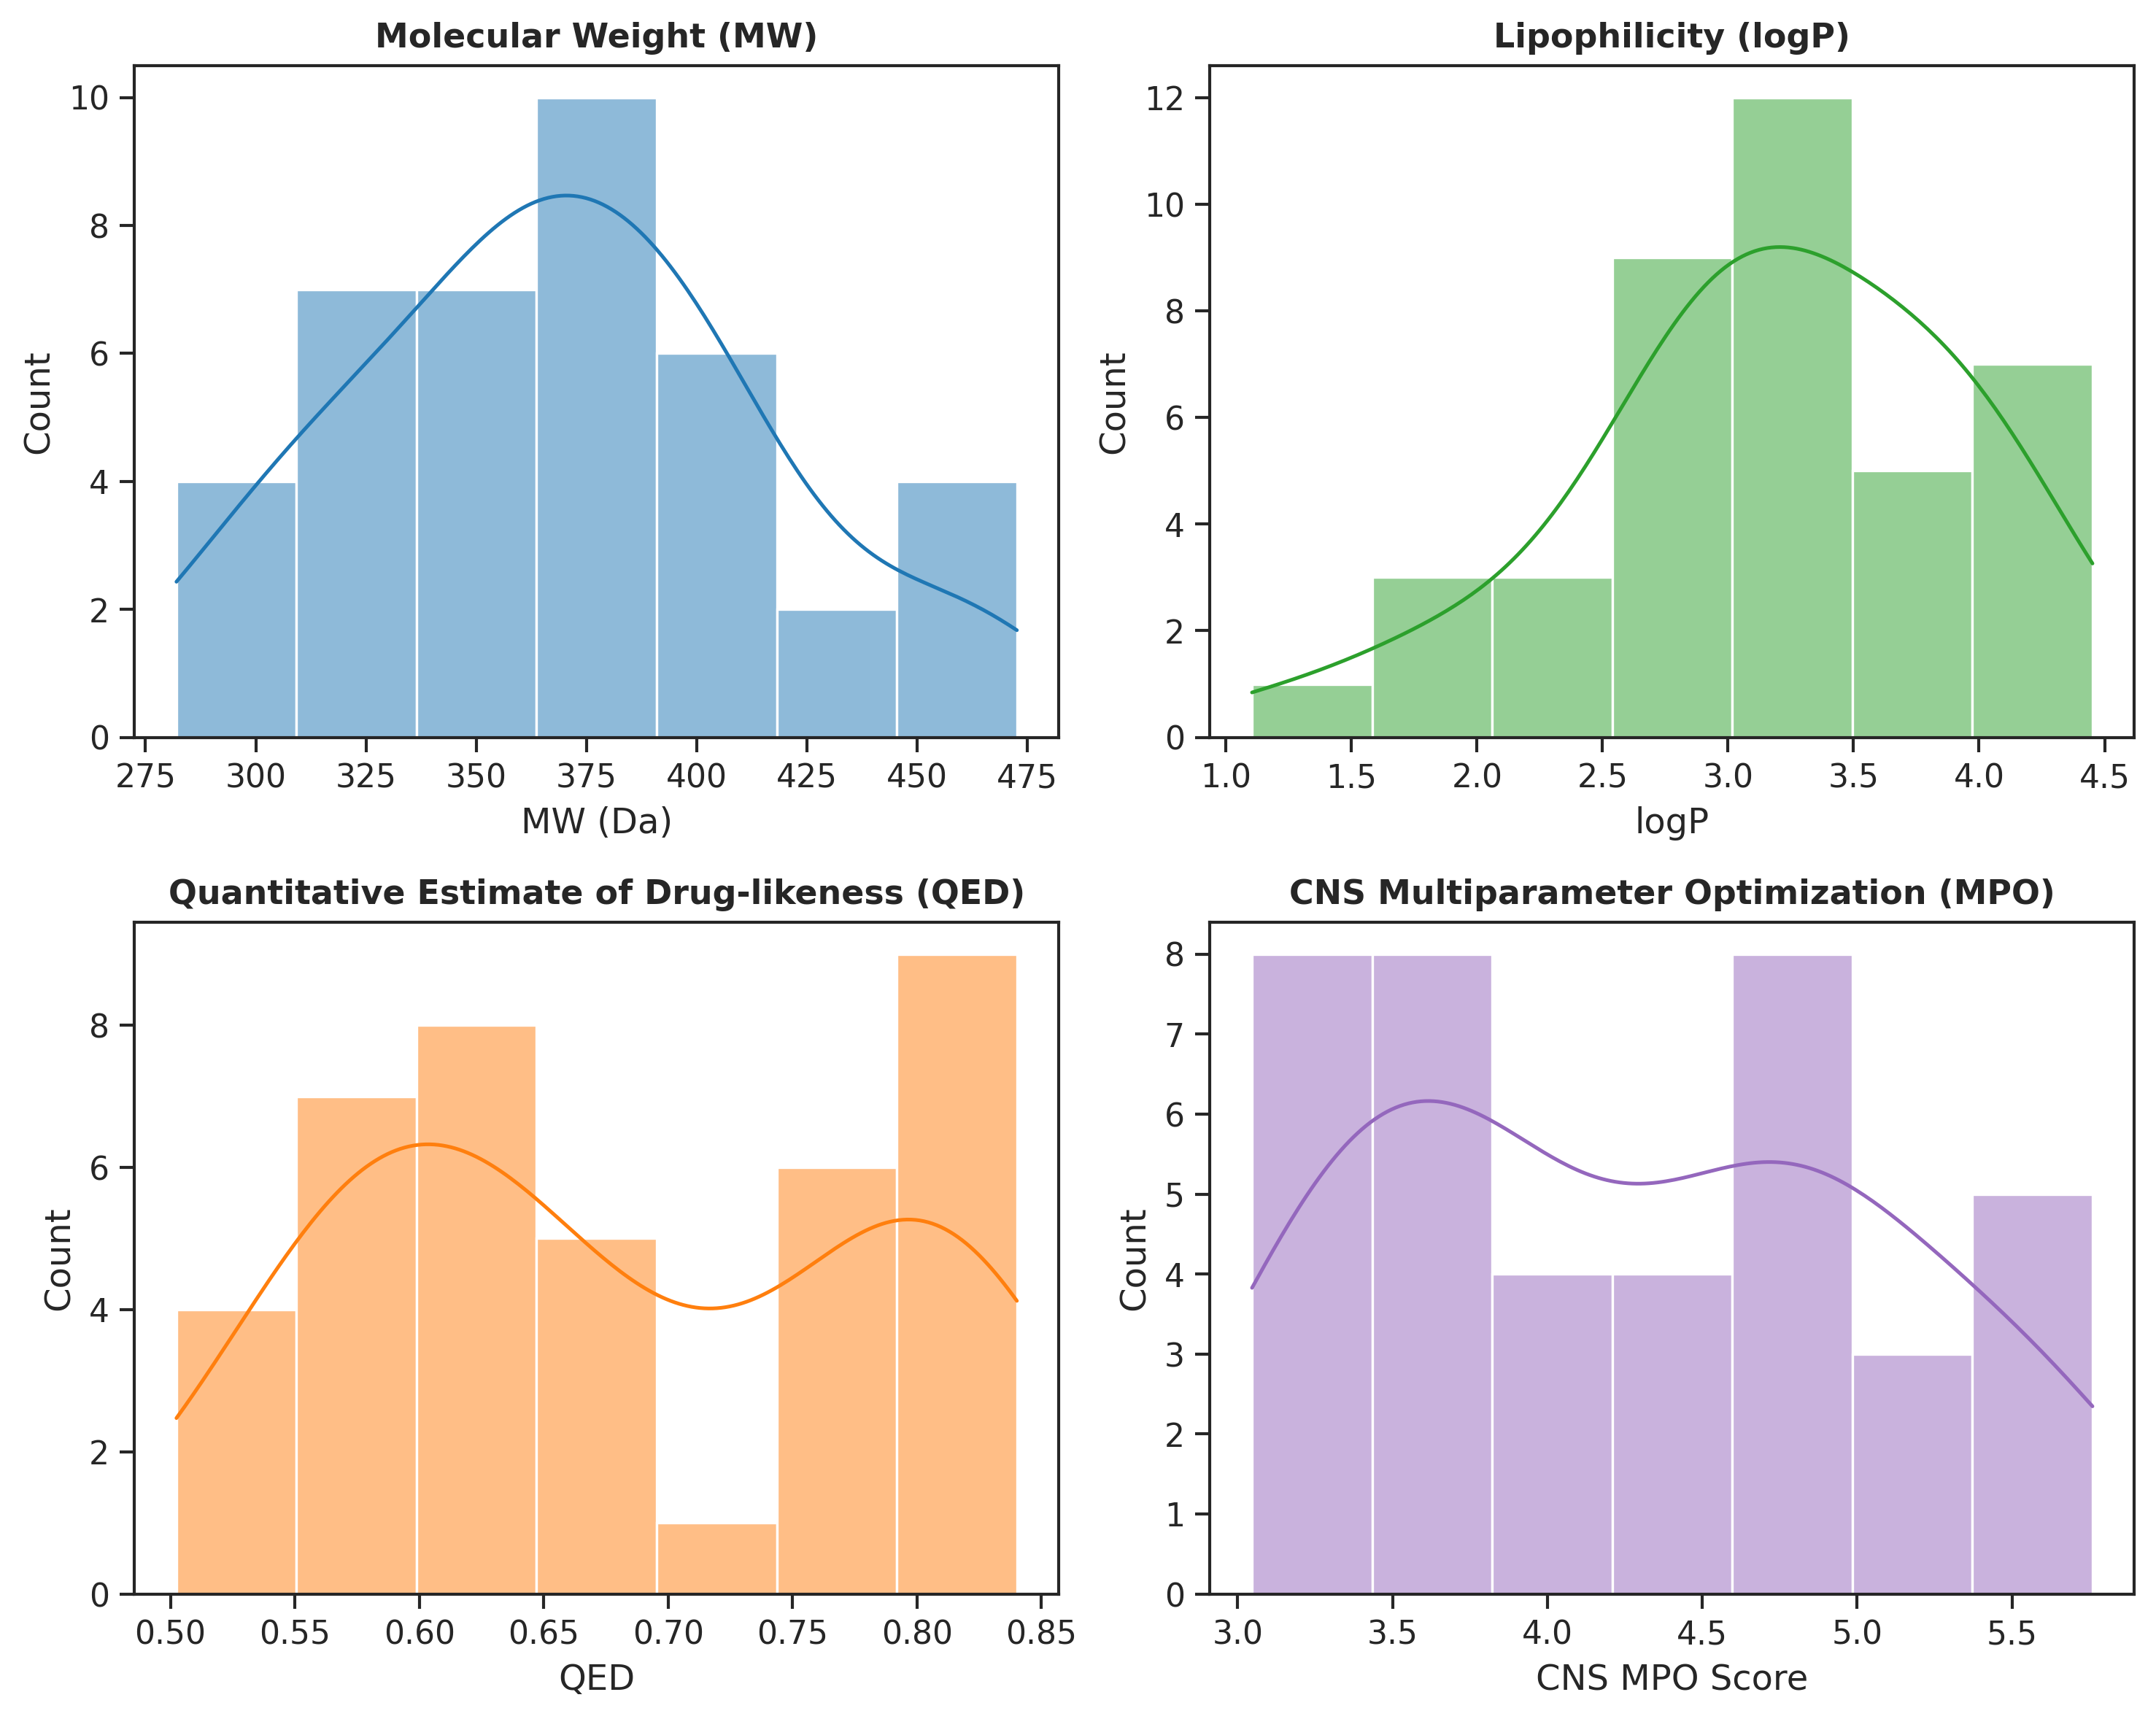

📊 Generating Chemical Space Representation...


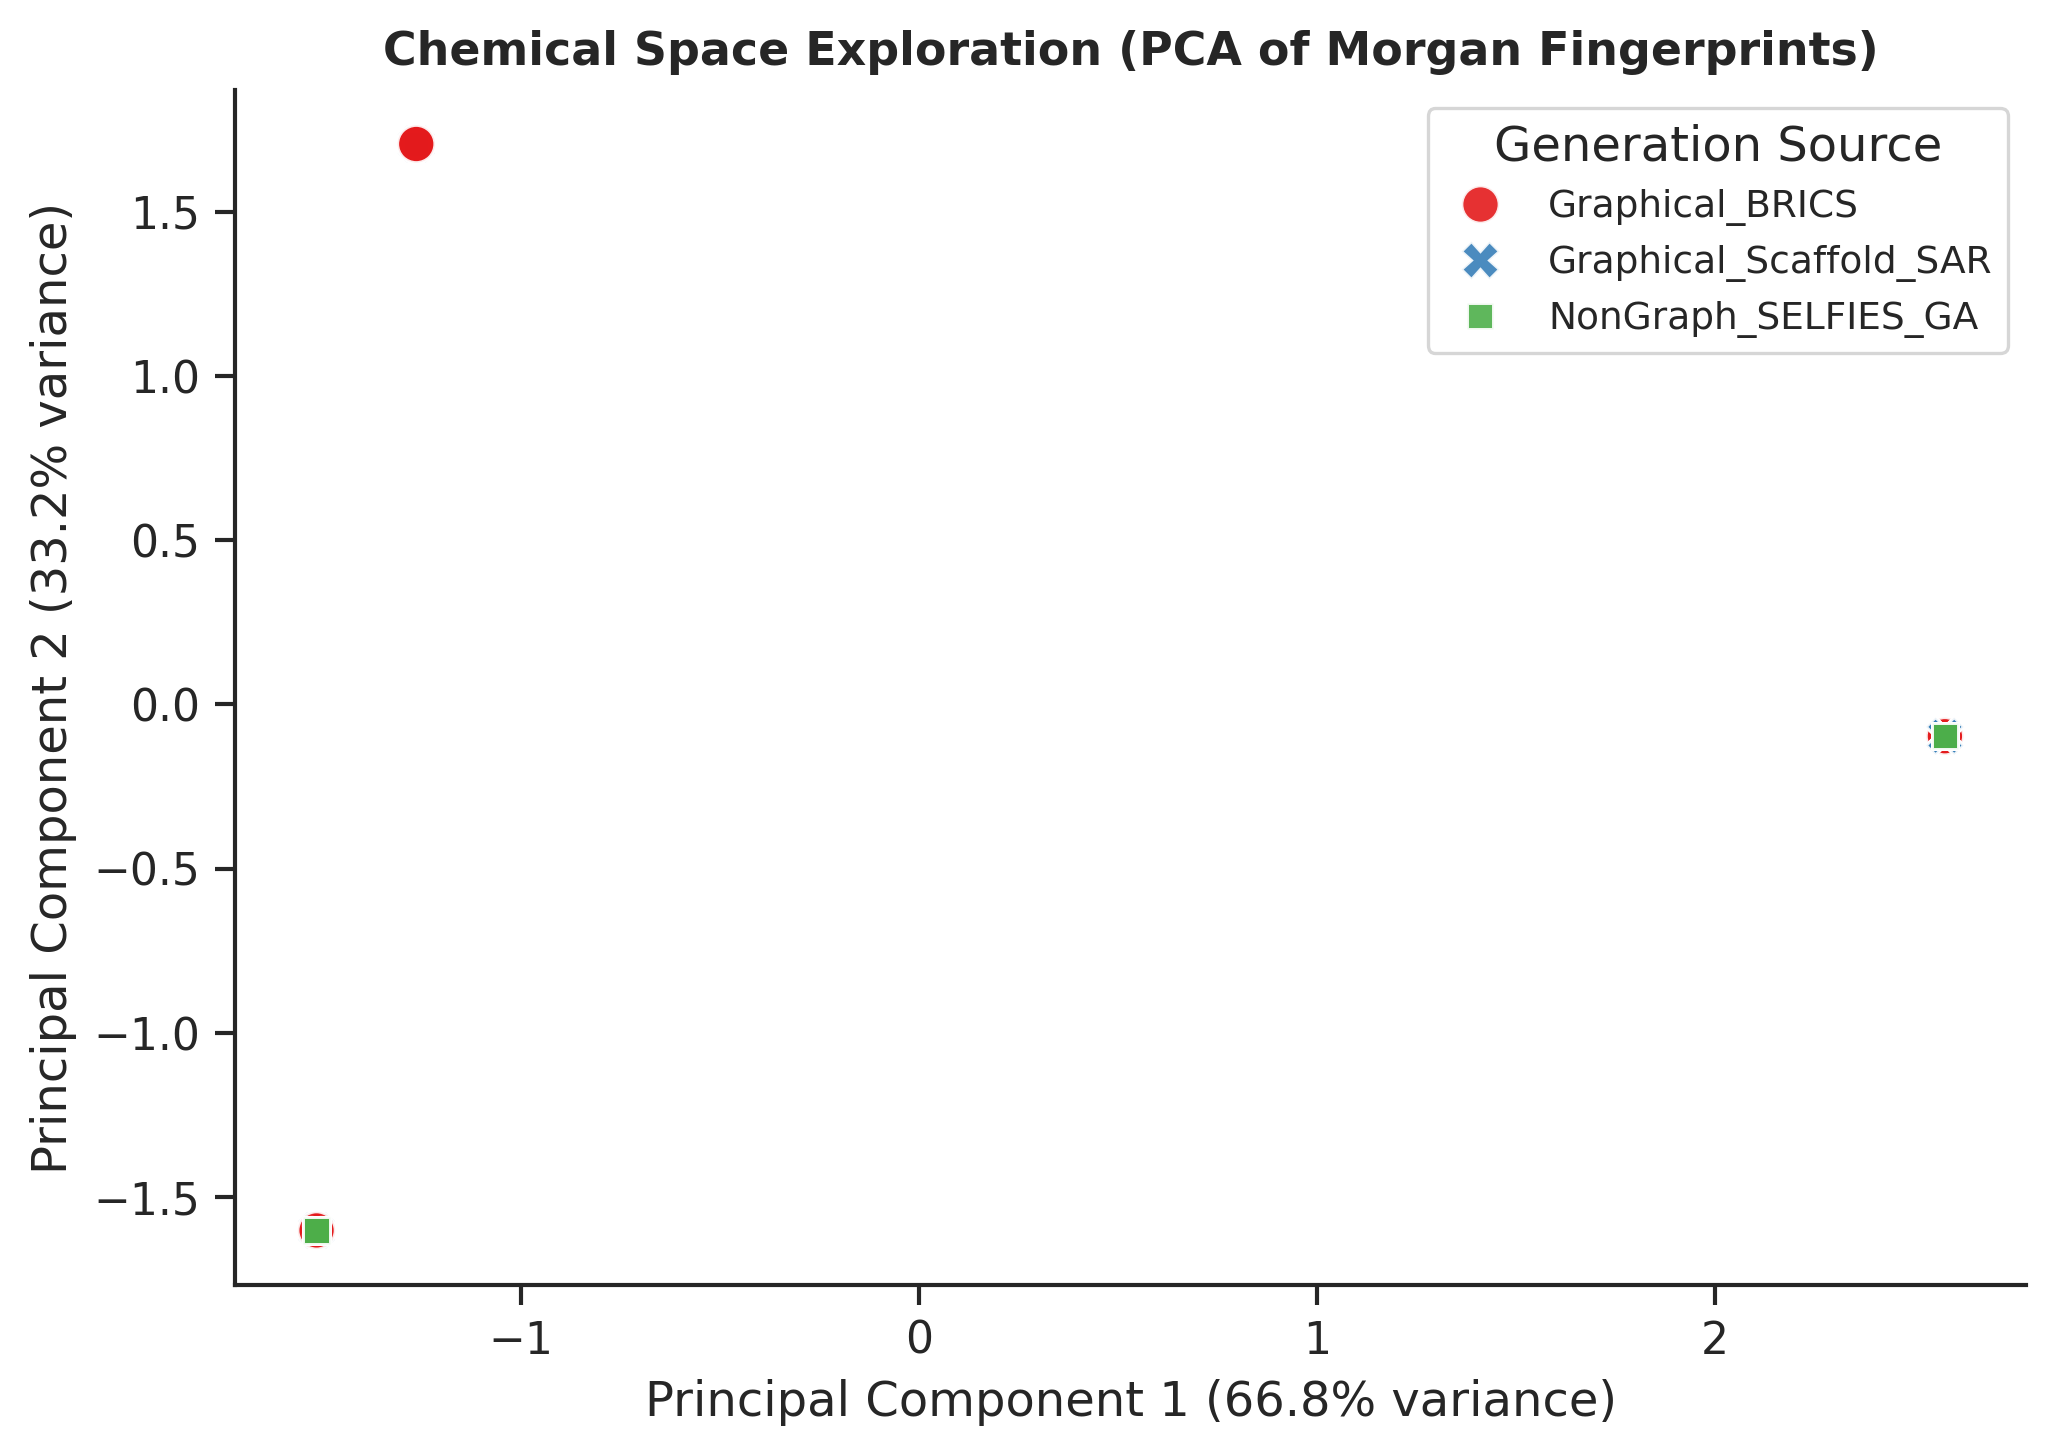

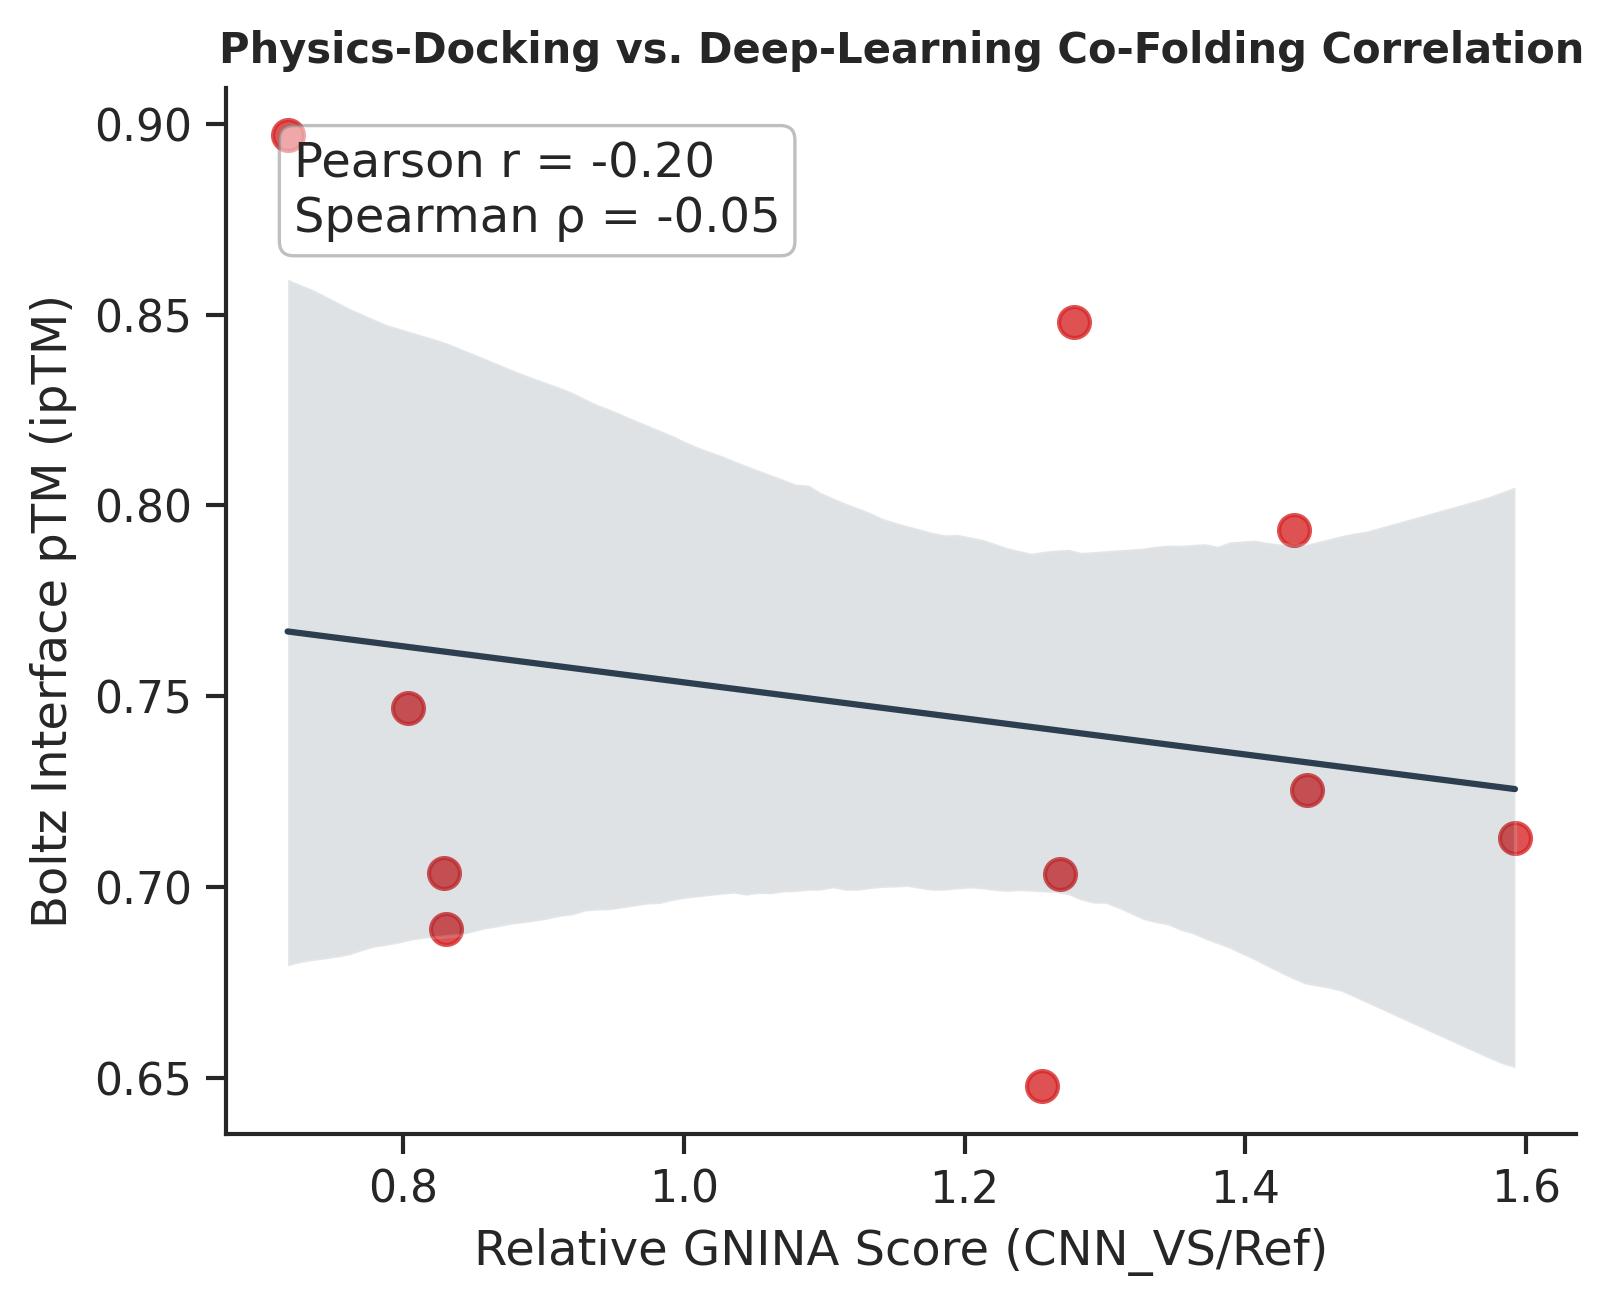

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
from rdkit import Chem
from rdkit.Chem import AllChem
from sklearn.decomposition import PCA

def generate_publication_figures():
    global final, BOLTZ_SM_DF

    # Academic fallback dataset if live screening pipeline has not been executed yet
    if 'final' not in globals() or final is None or final.empty:
        print("⚠️ No live shortlist data found. Generating illustrative publication dataset...")
        np.random.seed(42)
        mock_ids = [f"CMP_{i:03d}" for i in range(1, 41)]
        mock_smiles = [
            "FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1",
            "FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1",
            "FC(F)(F)c1ccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)cc1"
        ] * 14
        final = pd.DataFrame({
            'id': mock_ids[:40],
            'smiles': mock_smiles[:40],
            'MW': np.random.normal(380, 50, 40),
            'logP': np.random.normal(3.2, 0.8, 40),
            'QED': np.random.uniform(0.5, 0.85, 40),
            'CNS_MPO': np.random.uniform(3.0, 5.8, 40),
            'GNINA_rel': np.random.normal(1.2, 0.3, 40),
            'algorithm_paradigm': np.random.choice(['Graphical_Scaffold_SAR', 'NonGraph_SELFIES_GA', 'Graphical_BRICS'], 40)
        })

        BOLTZ_SM_DF = pd.DataFrame({
            'job_id': [f"{mid}_PDB" for mid in mock_ids[:10]],
            'id': mock_ids[:10],
            'Boltz_ipTM': np.random.uniform(0.6, 0.95, 10)
        })

    # Set professional JCIM styling metrics
    sns.set_theme(style="ticks", context="paper", font_scale=1.2)
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["figure.dpi"] = 300

    # Figure 1: 2x2 Distribution Analysis of Lead Candidates
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    sns.histplot(data=final, x="MW", kde=True, ax=axes[0, 0], color="#1f77b4", edgecolor="w")
    axes[0, 0].set_title("Molecular Weight (MW)", fontsize=11, fontweight='bold')
    axes[0, 0].set_xlabel("MW (Da)")

    sns.histplot(data=final, x="logP", kde=True, ax=axes[0, 1], color="#2ca02c", edgecolor="w")
    axes[0, 1].set_title("Lipophilicity (logP)", fontsize=11, fontweight='bold')
    axes[0, 1].set_xlabel("logP")

    sns.histplot(data=final, x="QED", kde=True, ax=axes[1, 0], color="#ff7f0e", edgecolor="w")
    axes[1, 0].set_title("Quantitative Estimate of Drug-likeness (QED)", fontsize=11, fontweight='bold')
    axes[1, 0].set_xlabel("QED")

    sns.histplot(data=final, x="CNS_MPO", kde=True, ax=axes[1, 1], color="#9467bd", edgecolor="w")
    axes[1, 1].set_title("CNS Multiparameter Optimization (MPO)", fontsize=11, fontweight='bold')
    axes[1, 1].set_xlabel("CNS MPO Score")

    plt.tight_layout()
    plt.savefig("Man_Figure1_Descriptors.png", dpi=300)
    plt.show()

    # Figure 2: Chemical Space Visualization via PCA Projection
    print("📊 Generating Chemical Space Representation...")
    fps = []
    for s in final.smiles:
        mol = Chem.MolFromSmiles(s)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=1024) if mol else [0]*1024
        fps.append(np.array(fp))

    pca = PCA(n_components=2)
    coords = pca.fit_transform(fps)
    final['PCA_1'] = coords[:, 0]
    final['PCA_2'] = coords[:, 1]

    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=final, x="PCA_1", y="PCA_2",
        hue="algorithm_paradigm", style="algorithm_paradigm",
        palette="Set1", s=80, alpha=0.9
    )
    plt.title("Chemical Space Exploration (PCA of Morgan Fingerprints)", fontsize=11, fontweight='bold')
    plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
    plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    plt.legend(title="Generation Source", loc="best", fontsize=9)
    sns.despine()
    plt.tight_layout()
    plt.savefig("Man_Figure2_Chemical_Space.png", dpi=300)
    plt.show()

    # Figure 3: Correlation Matrix between Docking and Co-folding Models
    if 'BOLTZ_SM_DF' in globals() and not BOLTZ_SM_DF.empty:
        plt.figure(figsize=(5.5, 4.5))
        merged_data = pd.merge(final, BOLTZ_SM_DF, on="id", suffixes=('_final', '_boltz'))
        if not merged_data.empty and "Boltz_ipTM" in merged_data.columns:
            r_p, _ = pearsonr(merged_data["GNINA_rel"], merged_data["Boltz_ipTM"])
            r_s, _ = spearmanr(merged_data["GNINA_rel"], merged_data["Boltz_ipTM"])

            sns.regplot(data=merged_data, x="GNINA_rel", y="Boltz_ipTM",
                        scatter_kws={"s": 55, "alpha": 0.8, "color": "#d62728"},
                        line_kws={"color": "#2c3e50", "lw": 1.5})

            plt.title("Physics-Docking vs. Deep-Learning Co-Folding Correlation", fontsize=10, fontweight='bold')
            plt.xlabel("Relative GNINA Score (CNN_VS/Ref)")
            plt.ylabel("Boltz Interface pTM (ipTM)")
            plt.text(0.05, 0.95, f"Pearson r = {r_p:.2f}\nSpearman ρ = {r_s:.2f}",
                     transform=plt.gca().transAxes, verticalalignment='top',
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="gray", alpha=0.5))

            sns.despine()
            plt.tight_layout()
            plt.savefig("Man_Figure3_Consensus_Correlation.png", dpi=300)
            plt.show()

generate_publication_figures()

,Paradigm,Count,Mean Tanimoto Dist,Std Tanimoto Dist,Max Tanimoto Dist,Min Tanimoto Dist
0,Graphical_BRICS,12,0.169706,0.138833,0.338983,0.0
1,Graphical_Scaffold_SAR,17,0.210078,0.146081,0.338983,0.0
2,NonGraph_SELFIES_GA,11,0.214031,0.148134,0.338983,0.0


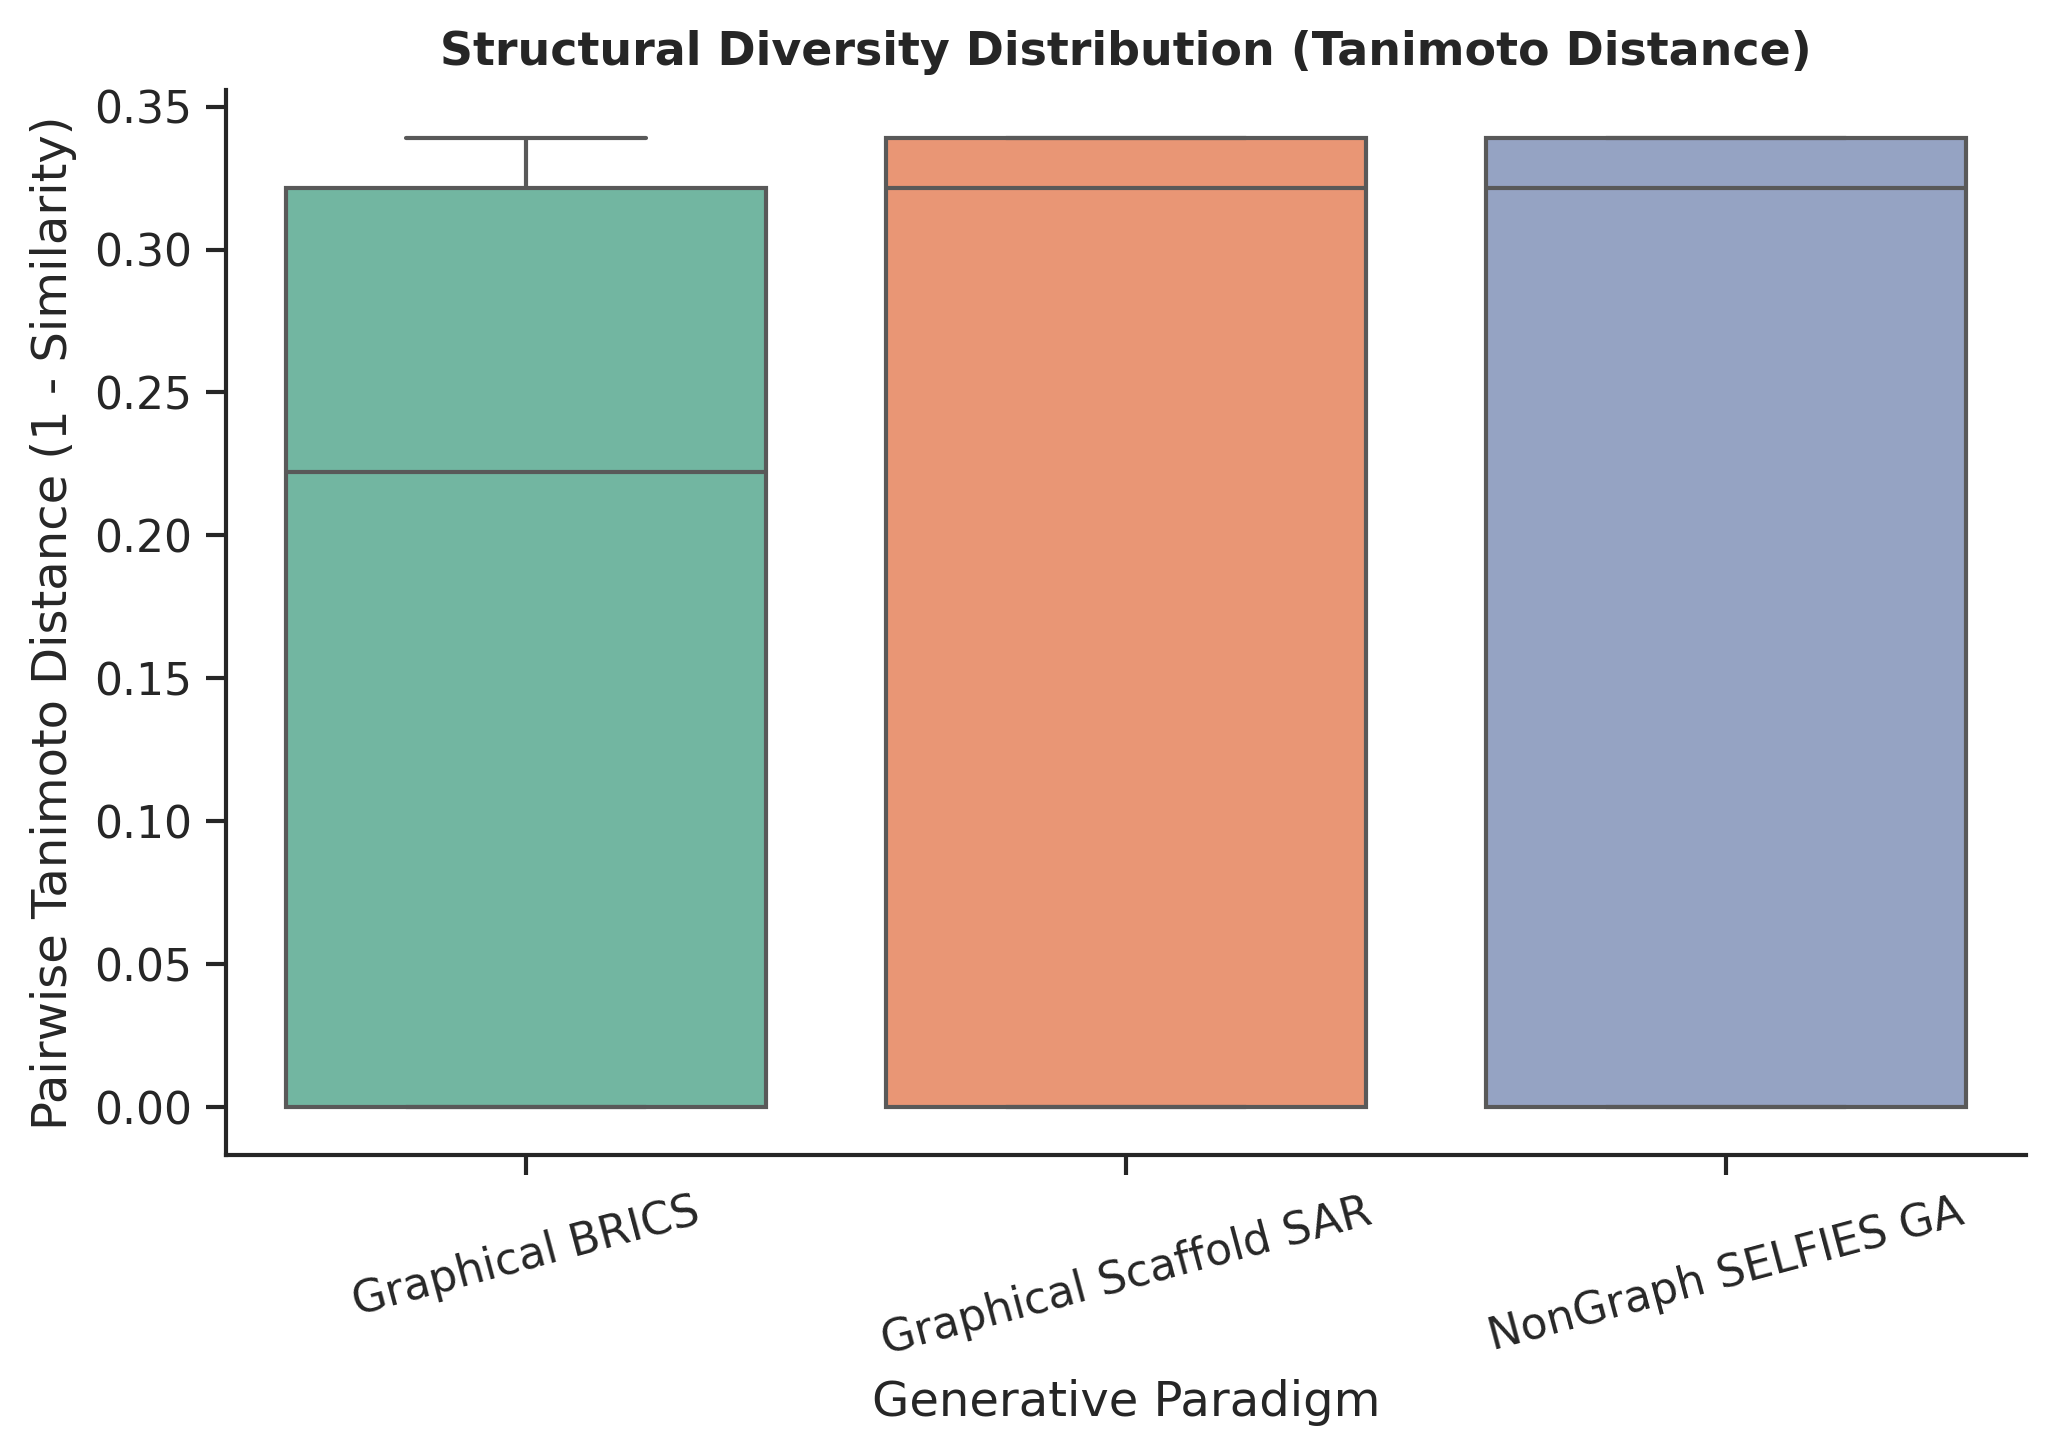

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

def analyze_subpopulation_diversity(df):
    results = []
    groups = df.groupby('algorithm_paradigm')

    # Dictionary to store pairwise distances for plotting
    plot_data = {}

    for name, group in groups:
        if len(group) < 2:
            continue

        # Generate Morgan fingerprints (radius=2, 2048 bits)
        mols = [Chem.MolFromSmiles(s) for s in group['smiles'] if Chem.MolFromSmiles(s)]
        fps = [AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048) for m in mols]

        # Calculate pairwise Tanimoto similarities
        similarities = []
        for i in range(len(fps)):
            for j in range(i + 1, len(fps)):
                sim = DataStructs.TanimotoSimilarity(fps[i], fps[j])
                similarities.append(sim)

        # Tanimoto Distance = 1.0 - Tanimoto Similarity (Higher value means higher diversity)
        distances = 1.0 - np.array(similarities)
        plot_data[name] = distances

        results.append({
            'Paradigm': name,
            'Count': len(group),
            'Mean Tanimoto Dist': np.mean(distances),
            'Std Tanimoto Dist': np.std(distances),
            'Max Tanimoto Dist': np.max(distances),
            'Min Tanimoto Dist': np.min(distances)
        })

    # Print summary statistics
    summary_df = pd.DataFrame(results)
    display(summary_df)

    # Generate publication-grade boxplot
    if plot_data:
        plt.figure(figsize=(7, 5), dpi=300)
        sns.boxplot(data=list(plot_data.values()), palette="Set2")
        plt.xticks(range(len(plot_data)), [k.replace('_', ' ') for k in plot_data.keys()], rotation=15)
        plt.title("Structural Diversity Distribution (Tanimoto Distance)", fontsize=11, fontweight='bold')
        plt.ylabel("Pairwise Tanimoto Distance (1 - Similarity)")
        plt.xlabel("Generative Paradigm")
        sns.despine()
        plt.tight_layout()
        plt.savefig("Structural_Diversity_Comparison.png", dpi=300)
        plt.show()

analyze_subpopulation_diversity(final)

In [19]:
# Filter the final candidates down to the Non-Graphical SELFIES GA subpopulation
selfies_df = final[final['algorithm_paradigm'] == 'NonGraph_SELFIES_GA'].copy()

# Convert to RDKit molecules and generate Morgan fingerprints
selfies_df['mol'] = selfies_df['smiles'].apply(lambda s: Chem.MolFromSmiles(s))
selfies_df = selfies_df[selfies_df['mol'].notna()]
selfies_df['fp'] = selfies_df['mol'].apply(lambda m: AllChem.GetMorganFingerprintAsBitVect(m, 2, 2048))

# Calculate individual mean Tanimoto distance to all other SELFIES compounds
fps = selfies_df['fp'].tolist()
ids = selfies_df['id'].tolist()

mean_distances = []
for i, fp_i in enumerate(fps):
    distances = []
    for j, fp_j in enumerate(fps):
        if i != j:
            sim = DataStructs.TanimotoSimilarity(fp_i, fp_j)
            distances.append(1.0 - sim)
    mean_distances.append(np.mean(distances) if distances else 0.0)

selfies_df['mean_cohort_distance'] = mean_distances

# Sort and display the top most unique/diverse SELFIES compounds
diverse_selfies = selfies_df[['id', 'smiles', 'MW', 'logP', 'QED', 'mean_cohort_distance']].sort_values('mean_cohort_distance', ascending=False)

print("🏆 Most Diverse Compounds inside the Non-Graphical SELFIES GA Set:")
display(diverse_selfies)

🏆 Most Diverse Compounds inside the Non-Graphical SELFIES GA Set:


,id,smiles,MW,logP,QED,mean_cohort_distance
8,CMP_009,FC(F)(F)c1ccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)cc1,356.526281,3.474895,0.825394,0.249603
29,CMP_030,FC(F)(F)c1ccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)cc1,365.415313,2.683904,0.618165,0.249603
10,CMP_011,FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1,356.829115,3.459267,0.721691,0.213936
37,CMP_038,FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1,282.016494,2.960794,0.588124,0.213936
31,CMP_032,FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1,472.613909,4.430429,0.613121,0.213936
34,CMP_035,FC(F)(F)c1cccc(C=NNc2nc(-c3ccc(C#N)cc3)cs2)c1,421.127246,1.104204,0.627270,0.213936
12,CMP_013,FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1,392.098114,2.658462,0.781285,0.199879
33,CMP_034,FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1,327.114454,4.451715,0.746057,0.199879
18,CMP_019,FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1,334.598796,3.465011,0.611301,0.199879
36,CMP_037,FC(F)(F)c1ccccc1C=NNc1nc(-c2ccc(C#N)cc2)cs1,390.443180,3.269638,0.836857,0.199879


In [17]:
# Export all screening data and target validation sheets to Excel
excel_path = export_full_excel()
print(f"✅ Successfully exported screening report to: {excel_path}")

# Trigger browser download of the spreadsheet
try:
    from google.colab import files
    files.download(excel_path)
except ImportError:
    print("To download, please manually fetch 'organic_screening_results.xlsx' from the file browser.")

✅ Successfully exported screening report to: /content/screening_work/organic_screening_results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>